# **SAMson: An Automated Brain Extraction Tool for Rodents Using SAM**  
*Accurate and robust rodent brain segmentation for MRI data*

---

### **Authored by**  
**Daniel Panadero Soler**<sup>1</sup>, **Mohamed Kotb Selim**<sup>1</sup>, **Patricia Martínez-Tazo**<sup>1</sup>,  
**Emma Muñoz-Moreno**<sup>2</sup>, **Pedro Ramos-Cabrer**<sup>3,4</sup>, **Pilar López-Larrubia**<sup>5</sup>,  
**Silvia De Santis**<sup>1</sup>, **Santiago Canals**<sup>1</sup>, and **Antonio Pertusa**<sup>6</sup>  

<sup>1</sup>Instituto de Neurociencias, CSIC-UMH, Sant Joan d’Alacant, Spain  
<sup>2</sup>IDIBAPS, Barcelona, Spain  
<sup>3</sup>CIC biomaGUNE, BRTA, Donostia–San Sebastián, Spain  
<sup>4</sup>Ikerbasque, Basque Foundation for Science, Bilbao, Spain  
<sup>5</sup>Instituto de Investigaciones Biomédicas Sols-Morreale, CSIC-UAM, Madrid, Spain  
<sup>6</sup>University Institute for Computer Research, University of Alicante, Alicante, Spain  

📧 **Contact**: [pertusa@ua.es](mailto:pertusa@ua.es)  

---

### **Abstract**
**Background and objective.** Accurate brain extraction is a critical step in the analysis of rodent head magnetic resonance imaging (MRI) data. However, current methods often encounter difficulties in handling the diverse range of imaging setups, resolutions, and experimental conditions that are commonly found in this field.  
**Methods.** Based on the Segment Anything Model (SAM), we introduce here SAMson (*SAM for Segmentation Of Neuroimages*), an automated tool for robust rodent brain extraction. SAMson integrates a bounding box generator and a mask prediction pipeline, offering fully automated and semi-automated modes to address varying experimental complexities.  
**Results.** The performance of SAMson was evaluated using seven multi-center rodent MRI [datasets](https://doi.org/10.20350/digitalCSIC/17000) annotated at the pixel level, which differed in terms of acquisition parameters, contrast (T2-weighted, T2\*-weighted and diffusion-weighted images), resolution, anteroposterior coverage and animal age groups. SAMson outperformed the nine methods tested, BET, BET4Animal, RBM, BEN, SHERM, ANTs, deepbet, MedSAM and SAM2, in segmentation accuracy (significantly in 87 of 90 dataset–method comparisons), with mean Jaccard indices of 89.0–94.7%. The semi-automated mode demonstrates particular efficacy in challenging scenarios, including low-resolution images and cases requiring refined mask precision.  
**Conclusions.** In contrast to conventional volumetric techniques, SAMson's errors are confined to a few individual slices, thereby enabling rapid and targeted correction when needed. By providing open-source access, SAMson aims to support large-scale research workflows and advance translational neuroscience. The curated data can be downloaded from https://doi.org/10.20350/digitalCSIC/17000, and the code is available at https://github.com/CanalsLab/SAMson, as an installable Python package (samson-mri) with a command-line interface, a Python API and a graphical application.

---

### **Contents**
This notebook reproduces every figure, table and statistic of the evaluation reported in the SAMson article (seven datasets, ten dataset-contrasts, 409 scans; SAMson and nine other methods). Every metric is read from the result files written by `SAMson_experiments.ipynb` (`results/exp_samson_subjects.csv`, `results/exp_samson_slices.csv`) and `SAMson_benchmark.ipynb` (`results/exp_tools_subjects.csv`, `results/exp_tools_slices.csv`, `results/sherm_runtimes.csv`); the run times and the computing environment of the full run are read from `results/runtimes.csv` and `results/environment.json` (written by `run_all.py`), and the dataset tables from `datasets/`. The notebook writes the three figures of the article that come from data (`notebooks/figures/fig2`, `fig4`, `fig5`) and its tables (CSV) to `notebooks/tables`.

| Manuscript | Section of this notebook | Output |
|---|---|---|
| Table 1 (datasets) | Data | `tables/datasets.csv` |
| Fig. 2 (SAMson Full-Auto and Semi-Auto, D1-D3) | 1. Figures | `figures/fig2.pdf`, `.png` |
| Fig. 4 (boxes; Oracle vs Full-Auto) | 1. Figures | `figures/fig4.pdf`, `.png` |
| Fig. 5 (benchmark) | 1. Figures | `figures/fig5.pdf`, `.png` |
| Table 2 (SAMson in every dataset-contrast) | 2.7 | `tables/samson_summary.csv`; every metric of SAMson Full-Auto, Semi-Auto, Oracle and boxes: `tables/samson_all_metrics.csv` |
| Section 3.3 (benchmark: tests of the Jaccard index; every metric of every method, the table summarised in the second paragraph; tests of 3D Dice and HD95) | 2.6 | `tables/benchmark_jaccard_tests.csv`, `tables/benchmark_all_metrics.csv`, `tables/benchmark_dice3d_hd95_tests.csv` |
| Text (Results, Methods 2.5-2.6, captions) | 2.1-2.8 and 3 | `tables/*.csv` and the printed values |

Conventions: the animal is the unit of analysis (the linear mixed models of 2.3 model slices with a random intercept per animal; scans of one animal averaged first: D5, 82 scans of 61 mice; D6, up to six sessions per mouse); evaluated slices: every slice with brain in the reference mask, in every dataset and for every method; differences in Jaccard % points (100 × Jaccard index) with 95% CIs; Holm correction within each family of tests. Fig. 5 and Section 3.3 use D1 restricted to the 3-month mice (n = 16); Table 2 uses all 53 D1 mice. SHERM: masks of two runs on other computers (D1, D3-D6: run 1; D2 and D7: run 2; `outputs/sherm/`).

## Setup

In [ ]:
import itertools                                                # combinations
import json                                                     # run environment
import os                                                       # paths
import warnings                                                 # warnings
from os.path import join as pjoin                               # paths
import matplotlib as mpl                                        # figure style
import matplotlib.pyplot as plt                                 # plots
import matplotlib.patches as mpatches                           # legend patches
import numpy as np                                              # arrays
import pandas as pd                                             # tables
import scipy                                                    # version
import seaborn as sns                                           # swarm plots
import statsmodels                                              # version
import statsmodels.formula.api as smf                           # linear mixed models
from matplotlib.lines import Line2D                             # legends
from scipy import stats                                         # statistical tests
from scipy.interpolate import make_interp_spline                # smooth bands
from statsmodels.stats.multitest import multipletests           # Holm correction
from statsmodels.stats.oneway import anova_oneway               # Welch ANOVA

warnings.filterwarnings("ignore", message=".*set_ticklabels.*")           # matplotlib tick label notices
warnings.filterwarnings("ignore", message=".*points cannot be placed.*")  # seaborn swarm placement notices
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", module="statsmodels.regression.mixed_linear_model")  # Boundary notices when the subject variance is ~0
warnings.filterwarnings("ignore", message=".*(normal approximation|Exact p-value).*")  # Wilcoxon notices with tied differences
warnings.filterwarnings("ignore", message="Maximum Likelihood optimization failed")  # MixedLM then retries with another optimizer (convergence: column 'converged')
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 300)

"""""  INPUTS  """""
P                     = os.path.abspath("..")                   # Release folder (this notebook is in <release>/notebooks)
results_path          = pjoin(P, "results")                     # Result files of SAMson_experiments and SAMson_benchmark; run times of the full run
figures_path          = pjoin(P, "notebooks", "figures")        # Article figures
tables_path           = pjoin(P, "notebooks", "tables")         # Tables (CSV)
DDOF = 1                  # Sample standard deviation (n - 1) in tables and figures
os.makedirs(figures_path, exist_ok=True)
os.makedirs(tables_path, exist_ok=True)

### Data
Per-slice and per-scan metrics of all methods, written by `SAMson_experiments.ipynb` and `SAMson_benchmark.ipynb` (evaluated slices: every slice with brain in the reference mask).

In [2]:
def load_results(path):
    """Slice and scan tables written by SAMson_experiments.ipynb and SAMson_benchmark.ipynb in a results folder."""
    read = lambda name: pd.read_csv(pjoin(path, name), dtype={"group": str, "session": str})
    slices = pd.concat([read("exp_samson_slices.csv"), read("exp_tools_slices.csv")], ignore_index=True)        # Slices 1-based, canonical order (1 = caudal)
    subjects = pd.concat([read("exp_samson_subjects.csv"), read("exp_tools_subjects.csv")], ignore_index=True)  # One row per scan
    for table in (slices, subjects):
        table["dc"] = table.dataset + "_" + table.contrast
    subjects["failure_rate_pct"] = 100 * subjects.failed_slices / subjects.n_slices
    subjects["abs_volume_bias_pct"] = subjects.volume_bias_pct.abs()
    return slices, subjects

slices_table, subjects_table = load_results(results_path)

GROUPS = ["3", "4.5", "6", "12", "D2_T2w", "D3_T2w"]                     # Groups of Figs. 2 and 4: D1 ages (months), D2, D3
DATASET_GROUPS = {"D1": ["3", "4.5", "6", "12"], "D2": ["D2_T2w"], "D3": ["D3_T2w"]}
DC_ORDER = ["D1_T2w", "D2_T2w", "D3_T2w", "D4_T2w", "D4_T2starw", "D4_DWI", "D5_DWI", "D6_T2w", "D6_BOLD", "D7_T2w"]  # Dataset-contrasts
SUBSETS = {**DATASET_GROUPS, "D1 (3)": ["3"], "D1_T2w": DATASET_GROUPS["D1"], **{dc: [dc] for dc in DC_ORDER[1:]}}  # Datasets, D1 3-month mice, dataset-contrasts
NAMES = {"full_auto": "SAMson", "semi_auto": "Semi-Auto", "oracle": "Oracle", "box": "Boxes", "sam2": "SAM2", "medsam": "MedSAM",
         "bet": "BET", "bet4animal": "BET4Animal", "rbm": "RBM", "ben": "BEN", "deepbet": "deepbet", "sherm": "SHERM", "ants": "ANTs"}

def values(method, dataset, column="jaccard"):
    """Animal values of a method in a dataset, dataset-contrast or subset (see SUBSETS), indexed by animal (D5, D6: mean of the scans of each animal)."""
    table = subjects_table[(subjects_table.method == method) & subjects_table.group.isin(SUBSETS[dataset])]
    return table.groupby("animal", sort=False)[column].mean()

def paired(method_a, method_b, dataset, column="jaccard"):
    """Values of two methods on the animals of a dataset evaluated with both, paired by animal."""
    both = pd.concat([values(method_a, dataset, column), values(method_b, dataset, column)], axis=1, join="inner").dropna()
    return both.iloc[:, 0].to_numpy(), both.iloc[:, 1].to_numpy()

def group_values(method, column="jaccard"):
    """Subject values of a method in each group of Figs. 2 and 4 (dict group -> array)."""
    table = subjects_table[subjects_table.method == method]
    return {g: table.loc[table.group == g, column].to_numpy() for g in GROUPS if (table.group == g).any()}

def slice_matrix(method, groups, column="jaccard"):
    """Scans x slices table of a method (slice numbers; empty where a slice was not evaluated in a scan)."""
    table = slices_table[(slices_table.method == method) & slices_table.group.isin(groups)]
    return table.pivot(index="scan", columns="slice", values=column).loc[table.scan.unique()].rename_axis(columns=None)

def per_slice_stats(method, groups):
    """Mean and SD across subjects of the Jaccard index of each slice (SD 0 at a slice evaluated in one subject only)."""
    matrix = slice_matrix(method, groups)
    return matrix.mean(), matrix.std(ddof=DDOF).fillna(0)

print("Scans per method and dataset-contrast (last row: animals):")
counts = subjects_table.pivot_table(index="method", columns="dc", values="scan", aggfunc="count").reindex(index=list(NAMES), columns=DC_ORDER)
counts.loc["animals"] = [len(values("full_auto", dc)) for dc in DC_ORDER]
counts.fillna(0).astype(int).rename(index=NAMES)

Scans per method and dataset-contrast (last row: animals):


dc,D1_T2w,D2_T2w,D3_T2w,D4_T2w,D4_T2starw,D4_DWI,D5_DWI,D6_T2w,D6_BOLD,D7_T2w
method,,,,,,,,,,
SAMson,53,10,12,15,15,15,82,96,95,16
Semi-Auto,53,10,12,15,15,15,82,96,95,16
Oracle,53,10,12,15,15,15,82,96,95,16
Boxes,53,10,12,15,15,15,82,96,95,16
SAM2,53,10,12,15,15,15,82,96,95,16
MedSAM,53,10,12,15,15,15,82,96,95,16
BET,53,10,12,15,15,15,82,96,95,16
BET4Animal,53,10,12,15,15,15,82,96,95,16
RBM,53,10,12,15,15,15,82,96,95,16


### Table 1: datasets
Animals (scans), sequence, TR/TE, FOV, matrix and resolution of every dataset-contrast, from the dataset tables (`datasets/datasets.tsv`: matrix and real voxel size of the published files; `datasets/acquisition.tsv`: acquisition parameters, as in Table 1 of the article). TE: D7 first-echo TE with the effective TE in parentheses; D4 T2\*w: TE of the first echo.

In [ ]:
datasets_table = pd.read_csv(pjoin(P, "datasets", "datasets.tsv"), sep="\t", dtype=str)
acquisition = pd.read_csv(pjoin(P, "datasets", "acquisition.tsv"), sep="\t", dtype=str).set_index("dataset_contrast")
rows = []
for _, r in datasets_table.iterrows():
    matrix, voxel = [int(v) for v in r.matrix.split("×")], [float(v) for v in r.real_voxel_size_mm.split("×")]
    acq = acquisition.loc[r.key]
    assert (int(r.n_animals), int(r.n_scans)) == (len(values("full_auto", r.key)), int(counts.loc["full_auto", r.key]))  # type: ignore
    rows.append({"dataset": r.dataset, "contrast": r.contrast, "animals (scans)": f"{r.n_animals} ({r.n_scans})", "sequence": acq.sequence_type,
                 "TR (ms)": acq.TR_ms, "TE (ms)": acq.TE_ms, "FOV (mm)": f"{matrix[0] * voxel[0]:.4g} × {matrix[1] * voxel[1]:.4g}",
                 "matrix": f"({matrix[0]} × {matrix[1]}) × {matrix[2]}", "resolution (mm)": f"({voxel[0]:.4g} × {voxel[1]:.4g}) × {voxel[2]:g}",
                 "scanner": acq.scanner, "field (T)": acq.field_T})
table1 = pd.DataFrame(rows).set_index(["dataset", "contrast"])
display(table1)
table1.to_csv(pjoin(tables_path, "datasets.csv"))

animals (scans)                                  sequence TR (ms)  TE (ms)     FOV (mm)            matrix            resolution (mm)  \
dataset contrast                                                                                                                                        
D1      T2w              53 (53)                        RARE (T2-weighted)    3000    7.698      18 × 15   (108 × 90) × 16    (0.1667 × 0.1667) × 0.8   
D2      T2w              10 (10)                        RARE (T2-weighted)    2500       33      20 × 20  (256 × 256) × 22  (0.07812 × 0.07812) × 0.7   
D3      T2w              12 (12)                        RARE (T2-weighted)    5500       26  17.5 × 17.5  (175 × 175) × 48          (0.1 × 0.1) × 0.3   
D4      T2w              15 (15)                        RARE (T2-weighted)    2500       40      23 × 23   (256 × 256) × 6    (0.08984 × 0.08984) × 1   
        T2starw          15 (15)              MGE (T2*-weighted), 1st echo  378.06    1.939      23 × 23   (128 × 128) × 6      (0.1797 × 0.1797) × 1   
        DWI              15 (15)   SE-EPI (diffusion-weighted), b = 0 vol.    3000    32.56      23 × 23   (128 × 128) × 6      (0.1797 × 0.1797) × 1   
D5      DWI              61 (82)  STEAM-EPI (diffusion-weighted), 1st vol.    8000     25.2      18 × 15   (108 × 90) × 16    (0.1667 × 0.1667) × 0.8   
D6      T2w              16 (96)                        RARE (T2-weighted)    2500       14      25 × 25  (200 × 200) × 22      (0.125 × 0.125) × 0.5   
        BOLD             16 (95)           GE-EPI (T2*-weighted), 1st vol.    2000   16.385      25 × 25  (100 × 100) × 22        (0.25 × 0.25) × 0.5   
D7      T2w              16 (16)                        RARE (T2-weighted)    4000  12 (48)      20 × 20  (384 × 384) × 16  (0.05208 × 0.05208) × 0.5   

                                                            scanner field (T)  
dataset contrast                                                               
D1      T2w                                    Bruker BioSpec 70/30         7  
D2      T2w       Bruker BioSpec 70/30 (actively shielded gradie...         7  
D3      T2w                               Bruker BioSpec USR 117/16      11.4  
D4      T2w                                    Bruker BioSpec 70/16         7  
        T2starw                                Bruker BioSpec 70/16         7  
        DWI                                    Bruker BioSpec 70/16         7  
D5      DWI                                    Bruker BioSpec 70/30         7  
D6      T2w                                    Bruker BioSpec 70/30         7  
        BOLD                                   Bruker BioSpec 70/30         7  
D7      T2w                                    Bruker BioSpec 70/30         7

### Functions

In [ ]:
"""""""""       STATISTICAL  FUNCTIONS       """""""""

def stars(p):
    """Significance label of a p-value."""
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""

def holm(p_values):
    """Holm-adjusted p-values."""
    return multipletests(p_values, method="holm")[1]

def ci_mean(x, level=0.95):
    """t-based confidence interval of a mean."""
    x = np.asarray(x, dtype=float)
    half = stats.t.ppf(0.5 + level / 2, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return x.mean() - half, x.mean() + half

def mean_ci(x, scale=100, digits=1):
    """'mean [t-based 95% CI]' of animal values."""
    x = scale * np.asarray(x, dtype=float)
    if not len(x):
        return "–"
    low, high = ci_mean(x)
    return f"{x.mean():.{digits}f} [{low:.{digits}f}, {high:.{digits}f}]"

def paired_comparison(a, b, scale=100):
    """
    Paired comparison of two methods on the same subjects (difference a - b, in Jaccard % points by default): mean
    difference with 95% CI, paired t-test, Cohen's dz, Shapiro-Wilk test of the differences, Wilcoxon signed-rank test
    and number of subjects with a > b.
    """
    a, b = scale * np.asarray(a), scale * np.asarray(b)
    d = a - b
    if np.ptp(d) < 1e-9:  # The same difference in every animal (e.g. failure rates of one slice or none): no variance, p = 0 unless it is 0
        zero, inf = abs(d[0]) < 1e-9, np.copysign(np.inf, d[0])
        return dict(n=len(d), mean_a=a.mean(), mean_b=b.mean(), difference=d.mean(), ci_low=d.mean(), ci_high=d.mean(), t=0.0 if zero else inf,
                    df=len(d) - 1, p=1.0 if zero else 0.0, dz=0.0 if zero else inf, shapiro_p=np.nan,
                    wilcoxon_p=1.0 if zero else stats.wilcoxon(a, b).pvalue, n_a_greater=int((d > 1e-9).sum()))  # type: ignore
    t = stats.ttest_rel(a, b)
    ci = t.confidence_interval()
    return dict(n=len(d), mean_a=a.mean(), mean_b=b.mean(), difference=d.mean(), ci_low=ci.low, ci_high=ci.high,
                t=t.statistic, df=len(d) - 1, p=t.pvalue, dz=d.mean() / d.std(ddof=1), shapiro_p=stats.shapiro(d).pvalue,
                wilcoxon_p=stats.wilcoxon(a, b).pvalue, n_a_greater=int((d > 0).sum()))  # type: ignore

def welch_comparison(a, b, scale=100):
    """Comparison of two independent samples: mean difference a - b with 95% CI, Welch t-test (Welch-Satterthwaite df) and Hedges' g."""
    a, b = scale * np.asarray(a), scale * np.asarray(b)
    t = stats.ttest_ind(a, b, equal_var=False)
    ci = t.confidence_interval()
    pooled_sd = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    g = (a.mean() - b.mean()) / pooled_sd * (1 - 3 / (4 * (len(a) + len(b)) - 9))
    return dict(n_a=len(a), n_b=len(b), mean_a=a.mean(), mean_b=b.mean(), difference=a.mean() - b.mean(),
                ci_low=ci.low, ci_high=ci.high, t=t.statistic, df=t.df, p=t.pvalue, hedges_g=g)  # type: ignore

def compare_methods(method_a, method_b, datasets=("D1", "D2", "D3")):
    """Paired comparison of two methods in each dataset, with Holm correction across datasets."""
    table = pd.DataFrame([dict(dataset=d, **paired_comparison(*paired(method_a, method_b, d))) for d in datasets]).set_index("dataset")  # type: ignore
    table["p_holm"], table["wilcoxon_p_holm"] = holm(table.p), holm(table.wilcoxon_p)
    return table

def show(table):
    """Display a results table with p-values in scientific notation."""
    out = table.copy()
    for column in out.columns:
        if column == "p" or column.startswith("p_") or column.endswith("_p") or "_p_" in column:
            out[column] = out[column].map(lambda p: f"{p:.2e}" if p < 0.001 else f"{p:.4f}")
    display(out.round(3))

def report(table, label):
    """One line per row in the format used in the article."""
    for name, r in table.iterrows():
        holm_p = f", Holm p = {r.p_holm:.2g}" if "p_holm" in r else ""
        print(f"{label} {name}: difference = {r.difference:+.2f} [{r.ci_low:.2f}, {r.ci_high:.2f}] Jaccard % points, "
              f"t({r.df:.4g}) = {r.t:.2f}, p = {r.p:.2g}{holm_p}")

def save(table, name):
    """Write a table to tables/<name>.csv."""
    table.to_csv(pjoin(tables_path, f"{name}.csv"))

In [ ]:
def age_analysis(method):
    """
    Effect of age on the animal Jaccard index in D1: descriptive statistics, one-way ANOVA with eta squared and Dunnett
    tests of each age group vs 12 months. Differences in Jaccard % points.
    """
    samples = {g: v for g, v in group_values(method).items() if g in DATASET_GROUPS["D1"]}
    data = list(samples.values())
    n, k = sum(map(len, data)), len(data)
    grand = np.concatenate(data).mean()
    eta2 = sum(len(x) * (x.mean() - grand) ** 2 for x in data) / sum(((x - grand) ** 2).sum() for x in data)
    anova = stats.f_oneway(*data)
    omnibus = pd.DataFrame([dict(test="One-way ANOVA (F, eta²)", statistic=anova.statistic, df=f"{k - 1}, {n - k}", p=anova.pvalue, effect=eta2)]).set_index("test")

    younger = [g for g in samples if g != "12"]
    dunnett = stats.dunnett(*[samples[g] for g in younger], control=samples["12"], random_state=0)  # fixed seed: the p-values use a randomised numerical integration  # type: ignore
    ci = dunnett.confidence_interval()
    dunnett_table = pd.DataFrame(dict(comparison=[f"{g} vs 12" for g in younger],
                                      difference=[100 * (samples[g].mean() - samples["12"].mean()) for g in younger],
                                      ci_low=100 * ci.low, ci_high=100 * ci.high, statistic=dunnett.statistic, p=dunnett.pvalue)).set_index("comparison")
    descriptive = pd.DataFrame({g: dict(n=len(x), mean=100 * x.mean(), sd=100 * x.std(ddof=DDOF)) for g, x in samples.items()}).T
    return dict(descriptive=descriptive, omnibus=omnibus, dunnett=dunnett_table)

def age_stars(method):
    """Significance labels of the Dunnett tests of each D1 group vs 12 months (Fig. 2)."""
    return {comparison.split(" vs ")[0]: stars(p) for comparison, p in age_analysis(method)["dunnett"].p.items() if stars(p)}  # type: ignore

In [ ]:
def box_mask_data(groups):
    """Box and Full-Auto mask Jaccard of every evaluated slice, with the relative anteroposterior position (0-1) of the slice in its scan."""
    table = slices_table[slices_table.group.isin(groups) & slices_table.method.isin(["box", "full_auto"])]
    data = table.pivot_table(index=["animal", "scan", "slice"], columns="method", values="jaccard").reset_index()
    return data.assign(position=data.groupby("scan").slice.transform(lambda s: (s - s.min()) / (s.max() - s.min())))

def fit_mixed(model):
    """REML fit of a mixed model, refitted with a derivative-free optimizer if the gradient-based ones do not converge."""
    fit = model.fit(reml=True)
    return fit if fit.converged else model.fit(reml=True, method="powell")

def mixed_model(data, formula="full_auto ~ box + C(slice)"):
    """Linear mixed model of the mask Jaccard with a random intercept per animal (and a variance component per scan where animals have several scans: D6)."""
    several_scans = data.groupby("animal").scan.nunique().max() > 1
    vc = dict(re_formula="1", vc_formula={"scan": "0 + C(scan)"}) if several_scans else {}
    return fit_mixed(smf.mixedlm(formula, data, groups=data["animal"], **vc))  # type: ignore

def box_mask_slopes(box_sets):
    """Per dataset (name -> groups): mixed-model slope of the slice mask Jaccard on the box Jaccard (with slice effects)."""
    rows, box_data = [], {}
    for name, groups in box_sets.items():
        data = box_data[name] = box_mask_data(groups)
        fit = mixed_model(data)
        low, high = fit.conf_int().loc["box"]
        rows.append(dict(dataset=name, animals=data.animal.nunique(), scans=data.scan.nunique(), slices=len(data), lmm_slope=fit.params["box"],
                         lmm_ci_low=low, lmm_ci_high=high, lmm_p=fit.pvalues["box"], converged=fit.converged))
    return pd.DataFrame(rows).set_index("dataset"), box_data

def slope_contrasts(names, box_data):
    """Between-dataset differences of the box slope in a joint mixed model (dataset-specific slopes and slice effects), Holm over the 3 pairs."""
    joint_data = pd.concat([box_data[d].assign(dataset=d, position_level=d + "_" + box_data[d].slice.astype(str)) for d in names], ignore_index=True)
    joint = mixed_model(joint_data, "full_auto ~ box:C(dataset) + C(position_level)")
    rows = []
    for first, second in itertools.combinations(names, 2):
        weights = pd.Series(0.0, index=joint.params.index)
        weights[f"box:C(dataset)[{second}]"] += 1
        weights[f"box:C(dataset)[{first}]"] -= 1
        difference, se = weights @ joint.params, np.sqrt(weights @ joint.cov_params() @ weights)
        rows.append(dict(contrast=f"{second} - {first}", slope_difference=difference, ci_low=difference - 1.96 * se, ci_high=difference + 1.96 * se,
                         p=2 * stats.norm.sf(abs(difference / se)), converged=joint.converged))
    table = pd.DataFrame(rows).set_index("contrast")
    table.insert(4, "p_holm", holm(table.p))
    return table

In [7]:
"""""""""       FIGURE  5:  BENCHMARK       """""""""

RANKED = ["full_auto", "sam2", "medsam", "bet", "bet4animal", "deepbet", "ben", "rbm", "ants", "sherm"]  # SAMson Full-Auto and the automated methods
REFERENCE_INFORMED = ["semi_auto", "oracle"]                                                              # Use the reference masks (not ranked)
FIG5_NAMES = {**NAMES, "full_auto": "SAMson Full-Auto", "semi_auto": "SAMson Semi-Auto", "oracle": "SAMson Oracle",
              "sam2": "SAM2 (SAMson boxes)", "medsam": "MedSAM (SAMson boxes)"}
SINGLE_DCS, MULTI_DCS = ["D1 (3)", "D2_T2w", "D3_T2w", "D5_DWI", "D7_T2w"], ["D4_T2w", "D4_T2starw", "D4_DWI", "D6_T2w", "D6_BOLD"]  # Top / bottom row
CONTRAST_LABELS = {"T2w": "T2w", "T2starw": "T2*w", "DWI": "dwMRI", "BOLD": "T2*w"}  # Contrast names of the manuscript
ACCENT, MUTED, INK, SOFT_INK, RULE = "#2a78d6", "#8f8d87", "#1f1f1d", "#52514e", "#dedcd6"
FIG5_STYLE = {"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "Nimbus Sans", "DejaVu Sans"], "font.size": 7,
              "axes.titlesize": 7, "axes.labelsize": 7, "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "axes.linewidth": 0.6,
              "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 0, "axes.edgecolor": SOFT_INK,
              "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 300, "figure.dpi": 150}
MM = 1 / 25.4
Y = {m: i for i, m in enumerate(RANKED)} | {m: len(RANKED) + 0.6 + i for i, m in enumerate(REFERENCE_INFORMED)}  # Row of each method

LABEL_GAP = 0.06  # Gap between SAMson's dot and its value label (fraction of the x range; larger than every SAMson CI half-width)

def dc_label(dc):
    """Display label of a dataset-contrast, e.g. 'D4 · DWI'; 'D1 (3)' is D1 restricted to the 3-month mice."""
    if dc == "D1 (3)":
        return "D1 (3 m.o.a.) · T2w"
    dataset, contrast = dc.split("_")
    return f"{dataset} · {CONTRAST_LABELS[contrast]}"

def dot_panel(ax, dc, xlim=(30, 100), xticks=(40, 60, 80, 100), label_gap=LABEL_GAP):
    """One dataset-contrast: mean (dot) and t-based 95% CI (whisker) across animals of the Jaccard index (%) of every method."""
    span = xlim[1] - xlim[0]
    for x in xticks:
        ax.axvline(x, color=RULE, lw=0.5, zorder=0)
    ax.axhline(len(RANKED) - 0.2, color=SOFT_INK, lw=0.5, ls=(0, (2, 2)))
    for method in RANKED + REFERENCE_INFORMED:
        x, y = 100 * values(method, dc).to_numpy(), Y[method]
        if not len(x):  # method without masks for this dataset-contrast
            ax.text(xlim[0] + 0.03 * span, y, "not run", va="center", fontsize=5.5, color=SOFT_INK, style="italic")
            continue
        mean, (low, high) = x.mean(), ci_mean(x)
        colour = ACCENT if method == "full_auto" else MUTED if method in RANKED else SOFT_INK
        ax.plot([max(low, xlim[0]), min(high, xlim[1])], [y, y], color=colour, lw=1.0 if method == "full_auto" else 0.8, solid_capstyle="butt", zorder=2)
        below = mean < xlim[0]  # Mean left of the axis: arrow and value at the left edge
        ax.plot(xlim[0] + 0.03 * span if below else mean, y, marker="<" if below else "o", ms=4.2 if method == "full_auto" else 3.4,
                mfc="white" if method in REFERENCE_INFORMED else colour, mec=colour, mew=0.8, zorder=3, clip_on=False)
        if below:
            ax.text(xlim[0] + 0.07 * span, y, f"{mean:.1f}", va="center", ha="left", fontsize=5.5, color=SOFT_INK)
        if method == "full_auto":  # SAMson's mean, at the same distance left of the dot in every panel (beyond its CI)
            ax.text(mean - label_gap * span, y - 0.05, f"{mean:.1f}", ha="right", va="center", fontsize=6, fontweight="bold", color=INK)
    ax.set_title(f"{dc_label(dc)} (n = {len(values('full_auto', dc))})", pad=3)
    ax.set_xlim(*xlim)
    ax.set_xticks(xticks)
    ax.set_xticklabels([f"{t:g}" for t in xticks])
    ax.set_ylim(max(Y.values()) + 0.6, -0.6)
    ax.set_yticks([Y[m] for m in RANKED + REFERENCE_INFORMED])
    ax.spines[["top", "right", "left"]].set_visible(False)

def figure5(path):
    """Fig. 5: one panel per dataset-contrast (top row: single-contrast datasets; bottom row: multi-contrast datasets), legend at
    the bottom (the notes on the points, whiskers and n are in the caption), saved as PDF and PNG."""
    methods = RANKED + REFERENCE_INFORMED
    animals = subjects_table[subjects_table.method == "full_auto"].groupby("dc").agg(scans=("scan", "size"), animals=("animal", "nunique"))
    print("Animal means over several scans (caption): " + "; ".join(f"{dc_label(dc)}: {r.scans} scans of {r.animals} animals"
                                                                   for dc, r in animals.reindex(DC_ORDER).iterrows() if r.scans > r.animals))
    gap = LABEL_GAP
    half = max(np.diff(ci_mean(100 * values("full_auto", dc).to_numpy())).item() / 2 for dc in SINGLE_DCS + MULTI_DCS)
    print(f"Largest SAMson whisker half-width (95% CI): {half:.2f} points; label gap {gap * 70:.1f} points")
    assert gap * 70 > half + 1
    with mpl.rc_context(FIG5_STYLE):
        fig = plt.figure(figsize=(190 * MM, 132 * MM))
        left, right = 0.165, 0.985
        grid = fig.add_gridspec(2, 5, left=left, right=right, top=0.955, bottom=0.135, wspace=0.12, hspace=0.30)
        for row, dcs in enumerate((SINGLE_DCS, MULTI_DCS)):
            for col, dc in enumerate(dcs):
                ax = fig.add_subplot(grid[row, col])
                dot_panel(ax, dc, label_gap=gap)
                ax.set_yticklabels([FIG5_NAMES[m] for m in methods] if col == 0 else [])
                for label, method in zip(ax.get_yticklabels() if col == 0 else [], methods):
                    label.set_fontweight("bold" if method == "full_auto" else "normal")
                    label.set_color(INK if method in RANKED else SOFT_INK)
        handles = [Line2D([], [], color=ACCENT, marker="o", ms=4.2, lw=1.0, label="SAMson Full-Auto"),
                   Line2D([], [], color=MUTED, marker="o", ms=3.4, lw=0.8, label="Comparators"),
                   Line2D([], [], color=SOFT_INK, marker="o", mfc="white", ms=3.4, lw=0.8, label="Use GT masks (not ranked)")]
        centre = (left + right) / 2
        fig.text(centre, 0.083, "Jaccard index (%)", ha="center", va="center", fontsize=7)
        fig.legend(handles=handles, loc="center", bbox_to_anchor=(centre, 0.032), ncol=3, frameon=False, fontsize=6.5,
                   handlelength=2.2, columnspacing=2.5, borderaxespad=0)
        for extension in ("pdf", "png"):
            fig.savefig(f"{path}.{extension}")
        plt.show()

In [ ]:
"""""""""       FIGURES  2  AND  4       """""""""

def redistribute_to_avoid_overlap(y_values, group_centers, min_separation=0.02):
    """Assign each value (in increasing order) to the x position of the group with fewest values closer than min_separation."""
    order = np.argsort(y_values)
    assigned = []
    for y in np.array(y_values)[order]:
        best_x, min_overlap = None, float('inf')
        for x in group_centers:
            overlap = sum(abs(y - other_y) < min_separation for assigned_x, other_y in assigned if assigned_x == x)
            if overlap < min_overlap:
                best_x, min_overlap = x, overlap
        assigned.append((best_x, y))
    positions = [None] * len(y_values)
    for rank, index in enumerate(order):
        positions[index] = assigned[rank]
    return positions

SLICE_TICKS = {"D1": (np.arange(1, 17), np.arange(2, 17, 2)), "D2": (np.arange(1, 23), np.arange(2, 23, 2)), "D3": (np.arange(2, 49), np.arange(5, 49, 5))}  # Slice numbers (1-based)

B_BLUE, B_ORANGE, B_RED, B_GREY = ACCENT, "#e07b2e", "#c8423b", "#9c9a94"
B_STYLE = {**FIG5_STYLE, "axes.spines.top": False, "axes.spines.right": False, "ytick.major.size": 2.5, "legend.frameon": False,
           "lines.solid_capstyle": "butt"}
ROWS_B = [("3", "D1 · 3 m.o.a."), ("4.5", "D1 · 4.5 m.o.a."), ("6", "D1 · 6 m.o.a."), ("12", "D1 · 12 m.o.a."), ("D2_T2w", "D2"), ("D3_T2w", "D3")]
TITLES_B = {"D1 (3)": "D1 · 3 m.o.a.", "D2": "D2", "D3": "D3"}
YLABEL = "Jaccard index (0,1)"
LEGEND_Y_FIG2, LEGEND_Y_FIG4 = 0.04, -0.005  # Vertical shift of the Mean/SD legend of panels 2a, 2c and 4a (axes fraction)

def b_frame(ax, y_lo, step, labelled_step):
    """Light horizontal grid every `step`, tick labels every `labelled_step`, thin left and bottom axes."""
    ticks = np.round(np.arange(y_lo, 1.0001, step), 3)
    for t in ticks:
        ax.axhline(t, color=RULE, lw=0.5, zorder=0)
    ax.set_ylim(y_lo, 1.0)
    ax.set_yticks(ticks)
    ax.set_yticklabels([f"{t:.1f}" if abs(round(t / labelled_step) * labelled_step - t) < 1e-6 else "" for t in ticks])

def b_letter(fig, ax, letter, dx=0.055, dy=0.004):
    """Bold panel letter at the top left of an axes (figure coordinates)."""
    box = ax.get_position()
    fig.text(box.x0 - dx, box.y1 + dy, letter, fontsize=9, fontweight="bold", va="bottom", ha="left", color=INK)

def b_animals(ax_l, ax_r, values, y_lo, stars=None, star_y=0.96, step=0.05, labelled=0.1, legend_y=0.0):
    """Panels a/c of Fig. 2 and a of Fig. 4: animals of the D1 ages (left) and of D2 and D3 (right), group mean ± SD, D1 mean ± SD band."""
    x_of = {g: x for g, x in zip(GROUPS, [0, 1, 2, 3, 0, 1])}
    groups = [g for g in GROUPS if g in values]
    for group in groups:
        x, y = zip(*redistribute_to_avoid_overlap(values[group], [x_of[group], x_of[group] + 0.15, x_of[group] - 0.15], min_separation=0.02))
        (ax_l if group in GROUPS[:4] else ax_r).scatter(x, y, s=8, color=B_BLUE, alpha=0.8, edgecolor="white", linewidth=0.3, zorder=2)
    d1 = np.concatenate([values[g] for g in groups if g in GROUPS[:4]])
    ax_l.axhspan(d1.mean() - d1.std(ddof=DDOF), d1.mean() + d1.std(ddof=DDOF), color=B_RED, alpha=0.08, lw=0, zorder=1, label="SD")
    ax_l.axhline(d1.mean(), color=B_RED, lw=0.8, ls=(0, (4, 2)), zorder=1, label="Mean")
    for group in groups:
        ax = ax_l if group in GROUPS[:4] else ax_r
        x, mean, sd = x_of[group], values[group].mean(), values[group].std(ddof=DDOF)
        ax.errorbar(x, mean, sd, color=B_ORANGE, lw=0.9, capsize=2.5, capthick=0.9, zorder=3)
        ax.hlines(mean, x - 0.2, x + 0.2, color=B_ORANGE, lw=1.4, zorder=3)
    for group, label in (stars or {}).items():
        ax_l.text(x_of[group], star_y, label, ha="center", va="center", fontsize=8, color=INK)
    for ax, labels in ((ax_l, ["3", "4.5", "6", "12"]), (ax_r, ["D2", "D3"])):
        b_frame(ax, y_lo, step, labelled)
        ax.set_xticks(range(len(labels)))
        ax.set_xticklabels(labels)
        ax.set_xlim(-0.6, len(labels) - 0.4)
        ax.tick_params(axis="x", length=0, pad=3)
    ax_r.spines["left"].set_visible(False)
    ax_r.tick_params(axis="y", length=0, labelleft=False)
    ax_l.set_xlabel("D1 (m.o.a.)")
    ax_l.set_ylabel(YLABEL)
    handles, labels = ax_l.get_legend_handles_labels()
    ax_l.legend(handles[::-1], labels[::-1], loc="lower left", bbox_to_anchor=(0, legend_y), fontsize=6.5, handlelength=1.8, borderaxespad=0.3)  # legend_y: entries on either side of a grid line

def b_slices(fig, axs, method, y_lo):
    """Panels b/d of Fig. 2 and b of Fig. 4: every slice of every animal (dots) and the per-slice mean (line), one row per D1 age, D2 and D3."""
    labelled = [np.arange(2, 17, 2)] * 4 + [np.arange(2, 23, 2), np.arange(5, 49, 5)]
    for k, (ax, (group, title)) in enumerate(zip(axs, ROWS_B)):
        matrix = slice_matrix(method, [group])
        sns.swarmplot(data=matrix, size=1.5 if k < 5 else 1.1, color=B_BLUE, alpha=0.85, linewidth=0, ax=ax, zorder=2)
        ax.plot(range(matrix.shape[1]), matrix.mean(), color=B_ORANGE, lw=0.9, marker="o", ms=1.8, zorder=3)
        b_frame(ax, y_lo, 0.1, 0.2)
        ax.set_xlim(-0.7, matrix.shape[1] - 0.3)
        ax.set_xticks(range(matrix.shape[1]))
        ax.set_xticklabels([str(s) if s in labelled[k] else "" for s in matrix.columns])
        ax.tick_params(axis="x", length=1.5, labelbottom=k >= 3)
        ax.set_title(title, loc="left", fontsize=6.5, pad=1.5, color=INK)
    axs[-1].set_xlabel("Slice")
    top, bottom = axs[0].get_position(), axs[-1].get_position()
    fig.text(top.x0 - 0.052, (top.y1 + bottom.y0) / 2, YLABEL, rotation=90, va="center", ha="center", fontsize=7)

def b_band(ax, mean, sd, color, label):
    """Per-slice mean (line) with a spline-smoothed ± SD band."""
    x = mean.index.to_numpy()
    x_smooth = np.linspace(x.min(), x.max(), 300)
    mean_smooth, sd_smooth = make_interp_spline(x, mean.to_numpy())(x_smooth), make_interp_spline(x, sd.to_numpy())(x_smooth)
    ax.fill_between(x_smooth, mean_smooth - sd_smooth, mean_smooth + sd_smooth, color=color, alpha=0.18, lw=0)
    ax.plot(x, mean, color=color, lw=1.0, marker="o", ms=2, label=label)

def b_pair(fig, ax0, ax1, method_a, method_b, dataset, tool_name, samson_label, stars_label=""):
    """Panels c-e of Fig. 4: animals of two methods joined per animal with mean ± SD (left) and per-slice mean ± SD (right)."""
    a, b = paired(method_a, method_b, dataset)  # type: ignore
    for y_a, y_b in zip(a, b):
        ax0.plot([0, 1], [y_a, y_b], color=B_GREY, lw=0.5, alpha=0.6, marker="o", ms=1.8, zorder=1)
    for x, y, color in ((0, a, B_ORANGE), (1, b, B_BLUE)):
        ax0.errorbar(x, np.mean(y), np.std(y, ddof=DDOF), color=color, lw=0.9, capsize=2.5, capthick=0.9, zorder=3)
        ax0.hlines(np.mean(y), x - 0.12, x + 0.12, color=color, lw=1.4, zorder=3)
    if stars_label:
        ax0.text(0.5, 0.965, stars_label, ha="center", va="center", fontsize=8, color=INK)
    ax0.set_xticks((0, 1))
    ax0.set_xticklabels((tool_name, samson_label))
    ax0.set_xlim(-0.45, 1.45)
    ax0.tick_params(axis="x", length=0, pad=3)
    ax0.set_ylabel(YLABEL)
    b_band(ax1, *per_slice_stats(method_b, SUBSETS[dataset]), B_BLUE, samson_label)
    b_band(ax1, *per_slice_stats(method_a, SUBSETS[dataset]), B_ORANGE, tool_name)
    ticks, labelled = SLICE_TICKS[dataset.split()[0]]
    ax1.set_xticks(ticks)
    ax1.set_xticklabels([str(t) if t in labelled else "" for t in ticks])
    ax1.tick_params(axis="x", length=1.5)
    ax1.set_xlabel("Slice")
    ax1.spines["left"].set_visible(False)
    ax1.tick_params(axis="y", length=0, labelleft=False)
    handles = [(mpatches.Patch(facecolor=c, alpha=0.18, lw=0), Line2D([], [], color=c, lw=1.0, marker="o", ms=2)) for c in (B_BLUE, B_ORANGE)]
    ax1.legend(handles, [samson_label, tool_name], loc="lower center", fontsize=6.5, handlelength=1.8, borderaxespad=0.3)
    for ax in (ax0, ax1):
        b_frame(ax, 0.4, 0.1, 0.2)
    ax1.set_title(TITLES_B[dataset], loc="left", fontsize=6.5, pad=2, color=INK)

def figure2(path):
    """Fig. 2: SAMson Full-Auto (a, b) and Semi-Auto (c, d) in D1 (by age), D2 and D3; saved as PDF and PNG."""
    with mpl.rc_context(B_STYLE):
        fig = plt.figure(figsize=(180 * MM, 215 * MM))
        outer = fig.add_gridspec(2, 2, left=0.085, right=0.985, top=0.955, bottom=0.045, wspace=0.27, hspace=0.13, height_ratios=[1, 2.55])
        for c, (method, star_y, heading) in enumerate((("full_auto", 0.96, "SAMson Full-Auto"), ("semi_auto", 0.965, "SAMson Semi-Auto"))):
            top = outer[0, c].subgridspec(1, 2, width_ratios=[2, 1], wspace=0.05)
            ax_l, ax_r = fig.add_subplot(top[0, 0]), fig.add_subplot(top[0, 1])
            b_animals(ax_l, ax_r, group_values(method), 0.6, stars=age_stars(method), star_y=star_y, legend_y=LEGEND_Y_FIG2)
            rows = outer[1, c].subgridspec(6, 1, hspace=0.62)
            axs = [fig.add_subplot(rows[k, 0]) for k in range(6)]
            for k in (1, 2, 3):
                axs[k].sharex(axs[0])
            b_slices(fig, axs, method, 0.6)
            box = ax_l.get_position()
            fig.text(box.x0, 0.985, heading, fontsize=7.5, fontweight="bold", va="top", ha="left", color=INK)
            b_letter(fig, ax_l, "ac"[c], dy=0.006)
            b_letter(fig, axs[0], "bd"[c], dy=0.012)
        for extension in ("pdf", "png"):
            fig.savefig(f"{path}.{extension}")
        plt.show()

def figure4(path, oracle_vs_full_3):
    """Fig. 4: box accuracy (a, b) and Oracle vs Full-Auto in D1 (3 m.o.a.), D2 and D3 (c-e; stars: Holm-adjusted paired t-tests of oracle_vs_full_3); saved as PDF and PNG."""
    with mpl.rc_context(B_STYLE):
        fig = plt.figure(figsize=(180 * MM, 205 * MM))
        outer = fig.add_gridspec(1, 2, left=0.085, right=0.985, top=0.975, bottom=0.045, wspace=0.24)
        left = outer[0, 0].subgridspec(2, 1, height_ratios=[1, 2.55], hspace=0.13)
        top = left[0, 0].subgridspec(1, 2, width_ratios=[2, 1], wspace=0.05)
        ax_l, ax_r = fig.add_subplot(top[0, 0]), fig.add_subplot(top[0, 1])
        b_animals(ax_l, ax_r, group_values("box"), 0.4, legend_y=LEGEND_Y_FIG4)  # y from 0.4, as panels b-e
        rows = left[1, 0].subgridspec(6, 1, hspace=0.62)
        axs = [fig.add_subplot(rows[k, 0]) for k in range(6)]
        for k in (1, 2, 3):
            axs[k].sharex(axs[0])
        b_slices(fig, axs, "box", 0.4)
        b_letter(fig, ax_l, "a", dy=0.006)
        b_letter(fig, axs[0], "b", dy=0.012)
        right = outer[0, 1].subgridspec(3, 1, hspace=0.24)
        for k, (dataset, letter) in enumerate(zip(("D1 (3)", "D2", "D3"), "cde")):
            pair = right[k, 0].subgridspec(1, 2, width_ratios=[1, 2], wspace=0.06)
            ax0, ax1 = fig.add_subplot(pair[0, 0]), fig.add_subplot(pair[0, 1])
            b_pair(fig, ax0, ax1, "oracle", "full_auto", dataset, "Oracle", "Full-Auto", stars(oracle_vs_full_3.p_holm[dataset]))
            b_letter(fig, ax0, letter, dy=0.008)
        for extension in ("pdf", "png"):
            fig.savefig(f"{path}.{extension}")
        plt.show()

# 1. Figures

## Fig. 2: SAMson Full-Auto (a, b) and Semi-Auto (c, d)
Animals of D1 (by age), D2 and D3 with the group mean ± SD and the mean ± SD of all D1 animals (a, c); every evaluated slice and the per-slice mean (b, d). Stars: Dunnett test of each age group vs 12 months (section 2.4). Slices: every slice with brain in the reference (D1: 1–16, D2: 1–21 or 22, D3: 2–5 to 48), numbered as in the image (1 = caudal). `figures/fig2.pdf`, `.png`.

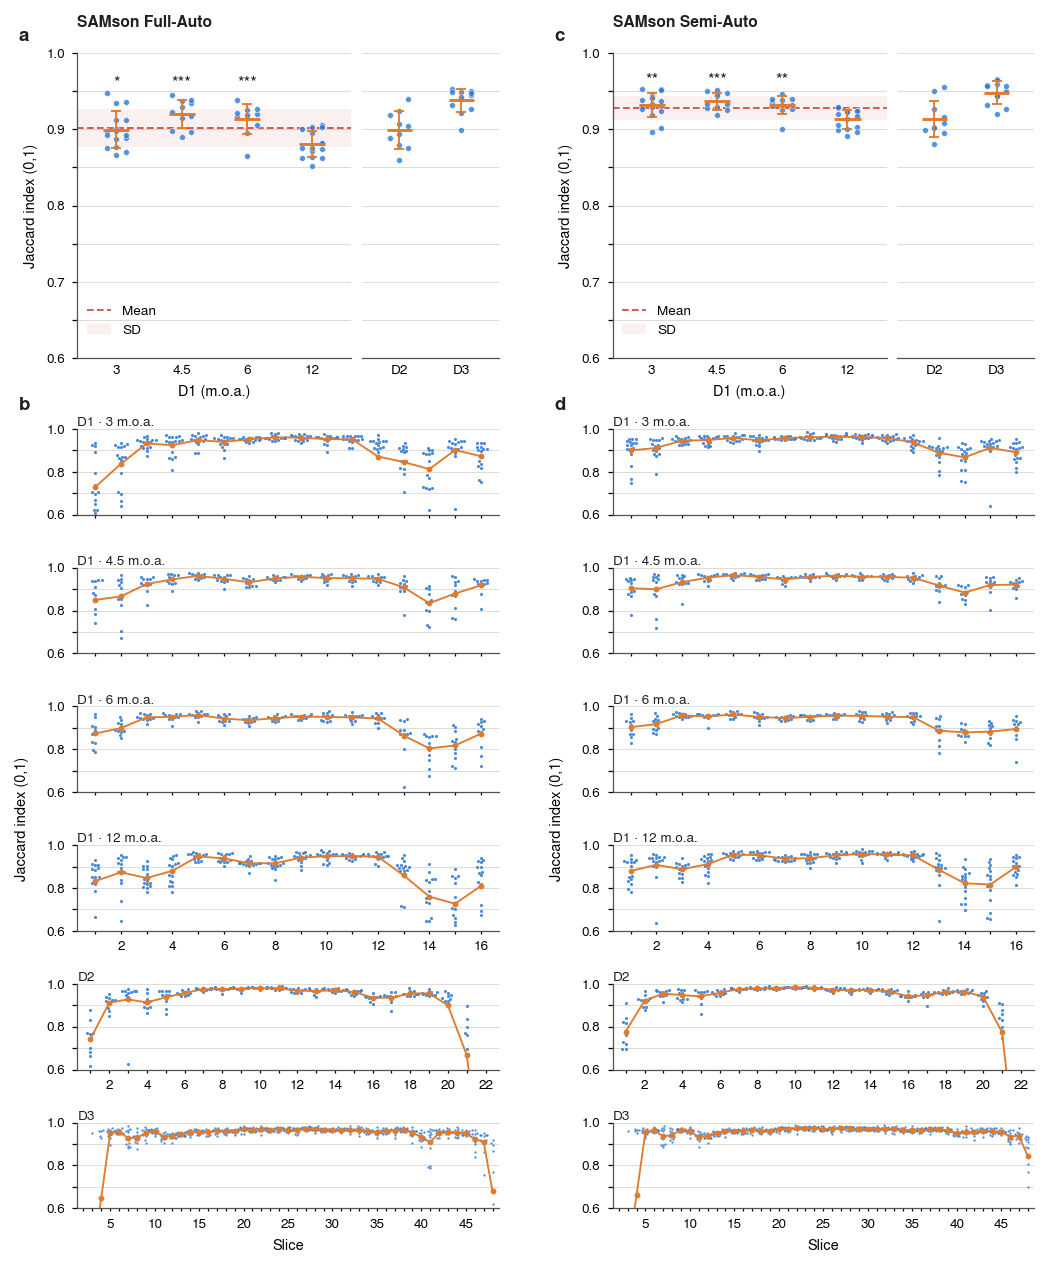

In [9]:
figure2(pjoin(figures_path, "fig2"))

## Fig. 4: object detector (a, b) and Oracle vs Full-Auto (c–e)
Box Jaccard of every animal and slice (a, b); Oracle vs Full-Auto in D1 restricted to the 3-month mice (n = 16), D2 and D3 (c–e). Stars: Holm-adjusted paired t-tests over D1 (3), D2 and D3 (section 2.5). `figures/fig4.pdf`, `.png`.

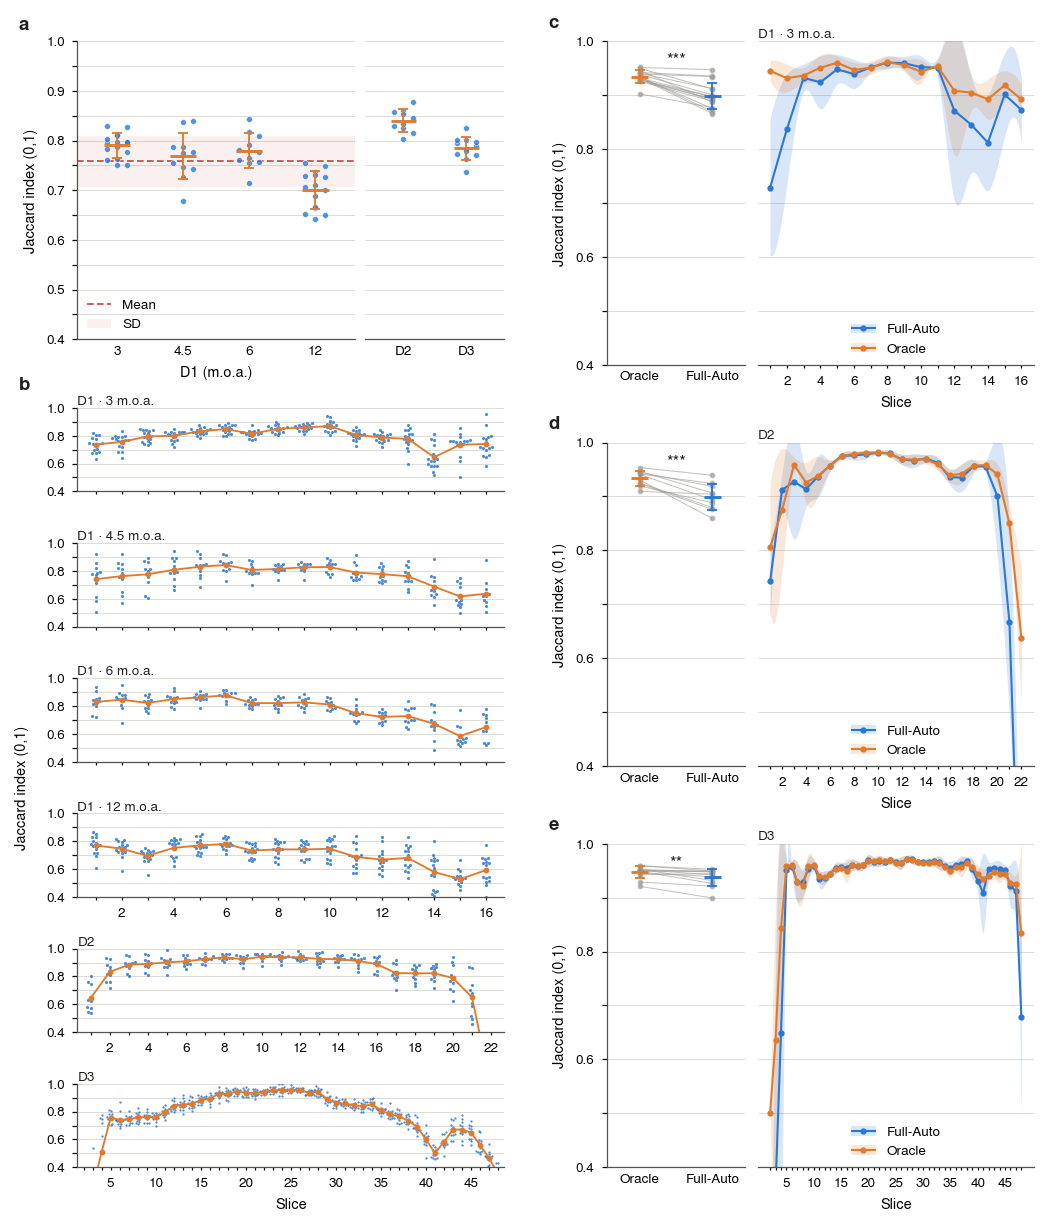

In [10]:
oracle_vs_full_3 = compare_methods("oracle", "full_auto", datasets=("D1 (3)", "D2", "D3"))
figure4(pjoin(figures_path, "fig4"), oracle_vs_full_3)

## Fig. 5: benchmark of all methods
Mean and t-based 95% CI across animals of the Jaccard index in each dataset-contrast; D1 restricted to the 3-month mice (n = 16), as in the comparison of D1–D3. Top row: single-contrast datasets (D1, D2, D3, D5, D7); bottom row: multi-contrast datasets (D4, D6). T2*-weighted images labelled T2*w and diffusion-weighted images dwMRI, as in the manuscript. `figures/fig5.pdf`, `.png`.

Animal means over several scans (caption): D5 · dwMRI: 82 scans of 61 animals; D6 · T2w: 96 scans of 16 animals; D6 · T2*w: 95 scans of 16 animals
Largest SAMson whisker half-width (95% CI): 1.96 points; label gap 4.2 points


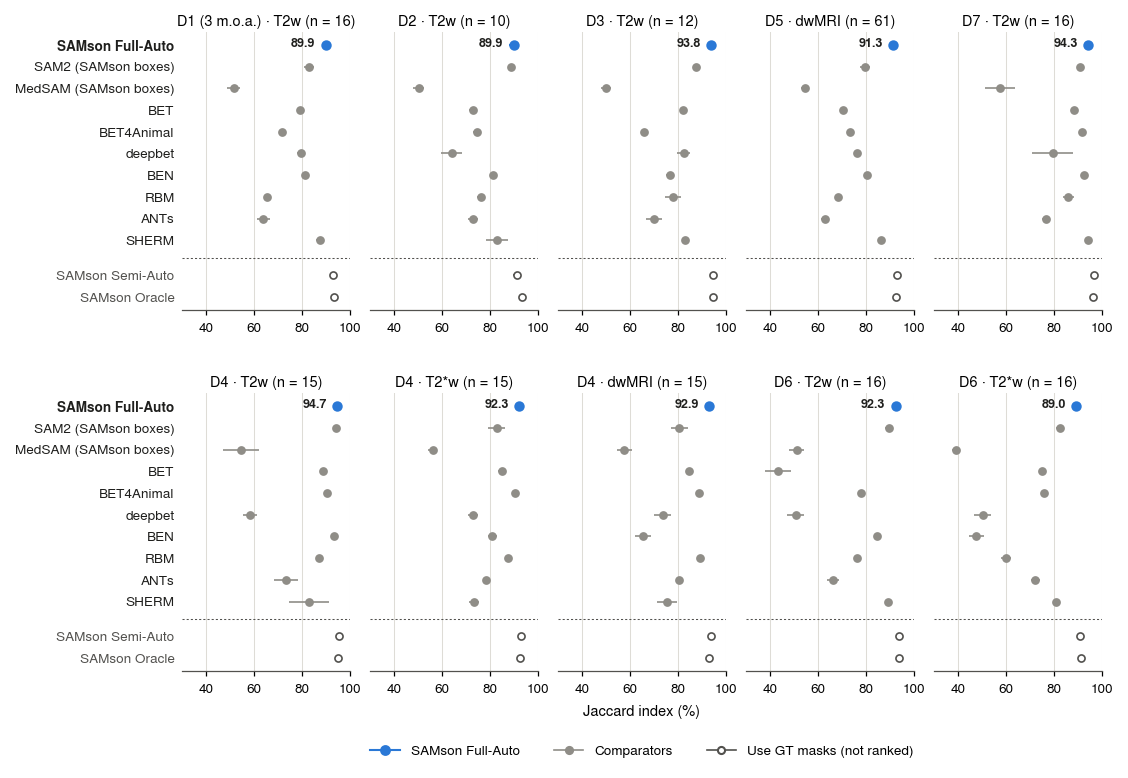

In [11]:
figure5(pjoin(figures_path, "fig5"))

# 2. Statistical Analyses
Unit of analysis: the animal (slice-mean Jaccard index of each scan, averaged over the scans of an animal in D5 and D6), except in section 2.3, where slices are analysed with mixed models that account for their grouping within animals (and scans). D1–D4 and D7 have one scan per animal per contrast; animals of different datasets are treated as independent. Differences are given in Jaccard % points (100 × Jaccard index) with 95% CIs.

Families for the Holm correction: (2.1) Semi-Auto vs Full-Auto in the 10 dataset-contrasts; (2.2) the 2 D2 vs D3 comparisons, the 5 measures (Welch ANOVAs) and the 3 dataset pairs of each measure of the resolution comparison; (2.3) the 3 between-dataset slope contrasts; (2.5) Oracle vs Full-Auto and Oracle vs Semi-Auto across D1 (3), D2 and D3, and Oracle vs Full-Auto across the 10 dataset-contrasts; (2.6) the comparisons of SAMson with the nine methods within each dataset-contrast; (2.7) the 3 contrast pairs of D4, and the 3 SAMson modes (D6). Dunnett tests (2.4) control the error rate within each analysis.

**Tests reported in the article.** Paired comparisons use the paired t-test (mean difference with its t-based 95% CI); the Wilcoxon signed-rank test (`wilcoxon_p`, `wilcoxon_p_holm`) and the Shapiro-Wilk test of the differences (`shapiro_p`) are given as sensitivity checks only (2.6 prints the Wilcoxon count of the benchmark).

## 2.1 Full-Auto vs Semi-Auto
Paired comparison on the same animals in the 10 dataset-contrasts (Holm over 10). Semi-Auto selects in each slice the best of the 3 candidate masks according to the reference mask, so it represents the best possible selection.

In [ ]:
semi_vs_full = compare_methods("semi_auto", "full_auto", datasets=DC_ORDER)
show(semi_vs_full)
report(semi_vs_full, "Semi-Auto vs Full-Auto")
save(semi_vs_full, "semi_vs_full")
print(f"Semi-Auto > Full-Auto in {(semi_vs_full.difference > 0).sum()}/{len(semi_vs_full)} dataset-contrasts, Holm p <= {semi_vs_full.p_holm.max():.2g}; "
      f"largest differences: " + ", ".join(f"{d} {v:.1f}" for d, v in semi_vs_full.difference.nlargest(2).items())
      + "; D4: " + ", ".join(f"{d} {v:.2f}" for d, v in semi_vs_full.difference.items() if d.startswith("D4")))  # type: ignore

,n,mean_a,mean_b,difference,ci_low,ci_high,t,df,p,dz,shapiro_p,wilcoxon_p,n_a_greater,p_holm,wilcoxon_p_holm
dataset,,,,,,,,,,,,,,,
D1_T2w,53,92.741,90.117,2.624,2.222,3.027,13.090,52,4.36e-18,1.798,0.0563,2.39e-10,53,4.36e-17,2.15e-09
D2_T2w,10,91.356,89.890,1.466,0.898,2.035,5.833,9,2.49e-04,1.845,0.2043,0.0020,10,7.47e-04,0.0020
D3_T2w,12,94.808,93.763,1.045,0.710,1.380,6.872,11,2.69e-05,1.984,0.3047,4.88e-04,12,1.34e-04,9.77e-04
D4_T2w,15,95.415,94.668,0.747,0.259,1.235,3.281,14,0.0055,0.847,0.0021,1.83e-04,14,0.0109,5.49e-04
D4_T2starw,15,92.967,92.321,0.646,0.485,0.807,8.585,14,5.97e-07,2.217,0.1833,6.10e-05,15,4.18e-06,3.05e-04
D4_DWI,15,93.620,92.929,0.691,0.432,0.949,5.726,14,5.24e-05,1.478,0.1831,6.10e-05,15,2.10e-04,3.05e-04
D5_DWI,61,92.755,91.338,1.417,1.080,1.755,8.403,60,1.01e-11,1.076,4.81e-09,1.17e-11,60,8.08e-11,1.17e-10
D6_T2w,16,93.785,92.309,1.476,1.053,1.900,7.431,15,2.11e-06,1.858,0.0411,3.05e-05,16,1.27e-05,2.44e-04
D6_BOLD,16,90.656,89.043,1.612,1.461,1.763,22.760,15,4.81e-13,5.690,0.0102,3.05e-05,16,4.33e-12,2.44e-04


Semi-Auto vs Full-Auto D1_T2w: difference = +2.62 [2.22, 3.03] Jaccard % points, t(52) = 13.09, p = 4.4e-18, Holm p = 4.4e-17
Semi-Auto vs Full-Auto D2_T2w: difference = +1.47 [0.90, 2.03] Jaccard % points, t(9) = 5.83, p = 0.00025, Holm p = 0.00075
Semi-Auto vs Full-Auto D3_T2w: difference = +1.05 [0.71, 1.38] Jaccard % points, t(11) = 6.87, p = 2.7e-05, Holm p = 0.00013
Semi-Auto vs Full-Auto D4_T2w: difference = +0.75 [0.26, 1.24] Jaccard % points, t(14) = 3.28, p = 0.0055, Holm p = 0.011
Semi-Auto vs Full-Auto D4_T2starw: difference = +0.65 [0.48, 0.81] Jaccard % points, t(14) = 8.58, p = 6e-07, Holm p = 4.2e-06
Semi-Auto vs Full-Auto D4_DWI: difference = +0.69 [0.43, 0.95] Jaccard % points, t(14) = 5.73, p = 5.2e-05, Holm p = 0.00021
Semi-Auto vs Full-Auto D5_DWI: difference = +1.42 [1.08, 1.75] Jaccard % points, t(60) = 8.40, p = 1e-11, Holm p = 8.1e-11
Semi-Auto vs Full-Auto D6_T2w: difference = +1.48 [1.05, 1.90] Jaccard % points, t(15) = 7.43, p = 2.1e-06, Holm p = 1.3e-05
Sem

## 2.2 Object detector accuracy
### D2 vs D3
D2 and D3 contain different mice, so they are compared with Welch tests (unequal variances; Welch-Satterthwaite degrees of freedom).

In [13]:
def d2_vs_d3_comparison():
    """Welch comparison of D2 and D3 (boxes and Full-Auto masks), Holm-corrected over the 2 tests."""
    table = pd.DataFrame({name: welch_comparison(values(method, "D2").to_numpy(), values(method, "D3").to_numpy())
                          for name, method in (("Boxes", "box"), ("Full-Auto masks", "full_auto"))}).T
    table["p_holm"] = holm(table.p)
    return table

d2_vs_d3 = d2_vs_d3_comparison()
show(d2_vs_d3)
report(d2_vs_d3, "D2 vs D3")
save(d2_vs_d3, "d2_vs_d3")

,n_a,n_b,mean_a,mean_b,difference,ci_low,ci_high,t,df,p,hedges_g,p_holm
Boxes,10.0,12.0,84.012,78.451,5.562,3.516,7.608,5.684,19.247,1.68e-05,2.343,3.36e-05
Full-Auto masks,10.0,12.0,89.890,93.763,-3.873,-5.780,-1.966,-4.334,14.762,6.11e-04,-1.859,6.11e-04


D2 vs D3 Boxes: difference = +5.56 [3.52, 7.61] Jaccard % points, t(19.25) = 5.68, p = 1.7e-05, Holm p = 3.4e-05
D2 vs D3 Full-Auto masks: difference = -3.87 [-5.78, -1.97] Jaccard % points, t(14.76) = -4.33, p = 0.00061, Holm p = 0.00061


### Resolution: D1 (3 m.o.a.) vs D6 T2w vs D7
T2w RARE images of the same field strength with increasing in-plane resolution: D1 at 3 m.o.a. (0.167 mm, n = 16), D6 T2w (0.125 mm, 16 mice, mean of each mouse's sessions) and D7 (0.052 mm, n = 16). Five animal measures (%): Full-Auto, Semi-Auto and Oracle Jaccard, box Jaccard and Oracle − Full-Auto. Welch ANOVA per measure (Holm over the 5 measures), then pairwise Welch tests with Hedges' g (Holm over the 3 pairs). Means with t-based 95% CIs.

In [ ]:
RESOLUTION = ["D1 (3)", "D6_T2w", "D7_T2w"]

def resolution_measures(dataset):
    """Animal values (%) of the five measures of the resolution comparison."""
    full, semi, oracle, box = (100 * values(m, dataset) for m in ("full_auto", "semi_auto", "oracle", "box"))
    return {"Full-Auto": full, "Semi-Auto": semi, "Oracle": oracle, "Boxes": box, "Oracle - Full-Auto": oracle - full}

measures = {d: resolution_measures(d) for d in RESOLUTION}
rows, pairs = [], []
for measure in measures[RESOLUTION[0]]:
    samples = [measures[d][measure].to_numpy() for d in RESOLUTION]
    welch = anova_oneway(samples, use_var="unequal")
    rows.append(dict(measure=measure, **{f"{d} (n = {len(x)})": mean_ci(x, scale=1, digits=2) for d, x in zip(RESOLUTION, samples)},
                     welch_F=welch.statistic, df=f"{welch.df[0]:.0f}, {welch.df[1]:.1f}", p=welch.pvalue))  # type: ignore
    table = pd.DataFrame([dict(measure=measure, pair=f"{second} - {first}", **welch_comparison(measures[second][measure], measures[first][measure], scale=1))
                          for first, second in itertools.combinations(RESOLUTION, 2)])
    table["p_holm"] = holm(table.p)
    pairs.append(table)
resolution = pd.DataFrame(rows).set_index("measure")
resolution_columns = dict(zip(RESOLUTION, resolution.columns[:3]))  # Dataset -> column of the means
resolution["p_holm"] = holm(resolution.p)
resolution_pairs = pd.concat(pairs).set_index(["measure", "pair"])
print("Mean [t-based 95% CI] (%) and Welch ANOVA:")
show(resolution)
print("Pairwise Welch tests:")
show(resolution_pairs)
save(resolution, "resolution")
save(resolution_pairs, "resolution_pairs")

Mean [t-based 95% CI] (%) and Welch ANOVA:


,D1 (3) (n = 16),D6_T2w (n = 16),D7_T2w (n = 16),welch_F,df,p,p_holm
measure,,,,,,,
Full-Auto,"89.93 [88.65, 91.21]","92.31 [91.44, 93.18]","94.34 [92.38, 96.30]",9.196,"2, 27.5",8.74e-04,0.0017
Semi-Auto,"93.18 [92.31, 94.04]","93.79 [93.23, 94.34]","96.54 [96.05, 97.03]",41.943,"2, 28.9",2.88e-09,1.44e-08
Oracle,"93.47 [92.85, 94.09]","93.56 [93.15, 93.97]","96.35 [95.73, 96.97]",35.061,"2, 28.8",1.94e-08,7.77e-08
Boxes,"79.03 [77.73, 80.33]","77.18 [75.34, 79.03]","84.90 [81.92, 87.88]",10.767,"2, 27.5",3.51e-04,0.0011
Oracle - Full-Auto,"3.54 [2.49, 4.59]","1.25 [0.65, 1.85]","2.01 [0.05, 3.97]",8.000,"2, 25.8",0.0020,0.0020


Pairwise Welch tests:


n_a  n_b  mean_a  mean_b  difference  ci_low  ci_high      t      df         p  hedges_g    p_holm
measure            pair                                                                                                               
Full-Auto          D6_T2w - D1 (3)   16   16  92.309  89.930       2.379   0.889    3.868  3.279  26.509    0.0029     1.130    0.0058
                   D7_T2w - D1 (3)   16   16  94.337  89.930       4.407   2.150    6.663  4.015  25.779  4.55e-04     1.384    0.0014
                   D7_T2w - D6_T2w   16   16  94.337  92.309       2.028  -0.067    4.123  2.014  20.720    0.0571     0.694    0.0571
Semi-Auto          D6_T2w - D1 (3)   16   16  93.785  93.178       0.607  -0.384    1.599  1.260  25.660    0.2191     0.434    0.2191
                   D7_T2w - D1 (3)   16   16  96.540  93.178       3.362   2.398    4.326  7.202  23.893  1.97e-07     2.482  3.95e-07
                   D7_T2w - D6_T2w   16   16  96.540  93.785       2.755   2.040    3.469  7.877  29.581  9.52e-09     2.715  2.86e-08
Oracle             D6_T2w - D1 (3)   16   16  93.560  93.471       0.090  -0.628    0.807  0.257  26.132    0.7995     0.088    0.7995
                   D7_T2w - D1 (3)   16   16  96.346  93.471       2.875   2.036    3.715  6.998  30.000  8.91e-08     2.412  1.78e-07
                   D7_T2w - D6_T2w   16   16  96.346  93.560       2.786   2.068    3.504  7.978  26.120  1.80e-08     2.749  5.41e-08
Boxes              D6_T2w - D1 (3)   16   16  77.185  79.029      -1.844  -4.019    0.330 -1.740  26.877    0.0932    -0.600    0.0932
                   D7_T2w - D1 (3)   16   16  84.897  79.029       5.867   2.691    9.044  3.847  20.481  9.70e-04     1.326    0.0019
                   D7_T2w - D6_T2w   16   16  84.897  77.185       7.712   4.323   11.101  4.686  25.058  8.37e-05     1.615  2.51e-04
Oracle - Full-Auto D6_T2w - D1 (3)   16   16   1.251   3.540      -2.289  -3.457   -1.121 -4.046  23.870  4.73e-04    -1.394    0.0014
                   D7_T2w - D1 (3)   16   16   2.009   3.540      -1.531  -3.690    0.628 -1.467  22.897    0.1559    -0.506    0.3117
                   D7_T2w - D6_T2w   16   16   2.009   1.251       0.758  -1.266    2.782  0.788  17.770    0.4413     0.271    0.4413

## 2.3 Relationship between box and mask accuracy (slice level)
Slices of the same mouse are not independent, and both box and mask accuracy depend on the anteroposterior position of the slice. Linear mixed models (random intercept per animal, one fixed effect per slice number; in D6 also a variance component per scan) estimate the change in mask Jaccard per unit of box Jaccard in each dataset, and a joint model (dataset-specific slopes and slice effects) tests whether these slopes differ between datasets (Wald tests, Holm over the 3 pairs). Datasets: D1 restricted to the 3-month mice, D2 and D3 (object detector), and the resolution datasets D1 (3), D6 T2w and D7.

In [15]:
box_sets = {"D1 (3)": ["3"], "D2": ["D2_T2w"], "D3": ["D3_T2w"], "D6_T2w": ["D6_T2w"], "D7_T2w": ["D7_T2w"]}
box_mask, box_data = box_mask_slopes(box_sets)
show(box_mask)
save(box_mask, "box_mask_slopes")

contrasts = []
for names in (("D1 (3)", "D2", "D3"), RESOLUTION):
    print(f"Slope contrasts of {', '.join(names)}:")
    table = slope_contrasts(names, box_data)
    show(table)
    contrasts.append(table.assign(datasets=", ".join(names)))
save(pd.concat(contrasts), "slope_contrasts")

,animals,scans,slices,lmm_slope,lmm_ci_low,lmm_ci_high,lmm_p,converged
dataset,,,,,,,,
D1 (3),16,16,256,0.522,0.351,0.692,2.16e-09,True
D2,10,10,217,0.335,0.209,0.461,2.04e-07,True
D3,12,12,541,0.884,0.800,0.969,8.85e-93,True
D6_T2w,16,96,1989,0.597,0.553,0.641,5.87e-157,True
D7_T2w,16,16,256,0.401,0.229,0.573,4.68e-06,True


Slope contrasts of D1 (3), D2, D3:


,slope_difference,ci_low,ci_high,p,p_holm,converged
contrast,,,,,,
D2 - D1 (3),-0.190,-0.385,0.006,0.0572,0.0572,True
D3 - D1 (3),0.359,0.190,0.528,3.15e-05,6.30e-05,True
D3 - D2,0.548,0.385,0.712,5.37e-11,1.61e-10,True


Slope contrasts of D1 (3), D6_T2w, D7_T2w:


,slope_difference,ci_low,ci_high,p,p_holm,converged
contrast,,,,,,
D6_T2w - D1 (3),0.052,-0.097,0.200,0.4957,0.5230,True
D7_T2w - D1 (3),-0.136,-0.374,0.101,0.2615,0.5230,True
D7_T2w - D6_T2w,-0.188,-0.384,0.008,0.0602,0.1807,True


## 2.4 Effect of age (D1): 12 months vs the rest
Each age group contains different mice: one-way ANOVA (F, eta²) and Dunnett tests of each group vs 12 months (the stars of Fig. 2), for the Full-Auto and Semi-Auto masks and for the box prompts.

In [16]:
for method in ("full_auto", "semi_auto", "box"):
    print(f"{'=' * 30} {NAMES[method]} {'=' * 30}")
    results = age_analysis(method)
    for name, table in results.items():
        print(name)
        show(table)
    save(pd.concat(results, names=["table"]), f"age_{method}")

============================== SAMson ==============================
descriptive


,n,mean,sd
3,16.0,89.930,2.395
4.5,11.0,92.024,1.863
6,11.0,91.316,1.962
12,15.0,88.037,1.727


omnibus


,statistic,df,p,effect
test,,,,
"One-way ANOVA (F, eta²)",9.852,"3, 49",3.41e-05,0.376


dunnett


,difference,ci_low,ci_high,statistic,p
comparison,,,,,
3 vs 12,1.893,0.122,3.664,2.601,0.0334
4.5 vs 12,3.986,2.030,5.943,4.958,2.50e-05
6 vs 12,3.278,1.322,5.235,4.078,4.87e-04


... (8 outputs left out)

omnibus


,statistic,df,p,effect
test,,,,
"One-way ANOVA (F, eta²)",18.737,"3, 49",3.12e-08,0.534


dunnett


,difference,ci_low,ci_high,statistic,p
comparison,,,,,
3 vs 12,8.970,5.832,12.109,6.955,1.91e-08
4.5 vs 12,6.785,3.319,10.252,4.763,4.95e-05
6 vs 12,7.890,4.423,11.356,5.538,3.29e-06


## 2.5 Oracle vs Full-Auto and Semi-Auto
Paired comparisons with Holm correction across D1 (3-month mice), D2 and D3 (Fig. 4c–e), then Oracle vs Full-Auto in all 10 dataset-contrasts.

In [17]:
print("Oracle vs Full-Auto, D1 restricted to 3-month mice (Fig. 4c-e)")
show(oracle_vs_full_3)
report(oracle_vs_full_3, "Oracle vs Full-Auto")
print("\nOracle vs Semi-Auto, D1 restricted to 3-month mice")
oracle_vs_semi_3 = compare_methods("oracle", "semi_auto", datasets=("D1 (3)", "D2", "D3"))
show(oracle_vs_semi_3)
report(oracle_vs_semi_3, "Oracle vs Semi-Auto")
print("\nAll dataset-contrasts: Oracle vs Full-Auto (Holm over 10)")
oracle_vs_full_all = compare_methods("oracle", "full_auto", datasets=DC_ORDER)
show(oracle_vs_full_all)
print(f"Oracle - Full-Auto: {oracle_vs_full_all.difference.min():+.2f} ({oracle_vs_full_all.difference.idxmin()}) to {oracle_vs_full_all.difference.max():+.2f} "
      f"({oracle_vs_full_all.difference.idxmax()}) Jaccard points")
save(pd.concat({"Oracle vs Full-Auto, D1 (3)": oracle_vs_full_3, "Oracle vs Semi-Auto, D1 (3)": oracle_vs_semi_3,
                "Oracle vs Full-Auto, all dataset-contrasts": oracle_vs_full_all}, names=["comparison"]), "oracle_comparisons")

Oracle vs Full-Auto, D1 restricted to 3-month mice (Fig. 4c-e)


,n,mean_a,mean_b,difference,ci_low,ci_high,t,df,p,dz,shapiro_p,wilcoxon_p,n_a_greater,p_holm,wilcoxon_p_holm
dataset,,,,,,,,,,,,,,,
D1 (3),16,93.471,89.930,3.540,2.494,4.587,7.209,15,3.03e-06,1.802,0.1409,3.05e-05,16,9.08e-06,9.16e-05
D2,10,93.364,89.890,3.474,2.061,4.888,5.560,9,3.52e-04,1.758,0.8683,0.0020,10,7.03e-04,0.0039
D3,12,94.690,93.763,0.927,0.398,1.457,3.856,11,0.0027,1.113,0.1019,0.0024,10,0.0027,0.0039


Oracle vs Full-Auto D1 (3): difference = +3.54 [2.49, 4.59] Jaccard % points, t(15) = 7.21, p = 3e-06, Holm p = 9.1e-06
Oracle vs Full-Auto D2: difference = +3.47 [2.06, 4.89] Jaccard % points, t(9) = 5.56, p = 0.00035, Holm p = 0.0007
Oracle vs Full-Auto D3: difference = +0.93 [0.40, 1.46] Jaccard % points, t(11) = 3.86, p = 0.0027, Holm p = 0.0027

Oracle vs Semi-Auto, D1 restricted to 3-month mice


,n,mean_a,mean_b,difference,ci_low,ci_high,t,df,p,dz,shapiro_p,wilcoxon_p,n_a_greater,p_holm,wilcoxon_p_holm
dataset,,,,,,,,,,,,,,,
D1 (3),16,93.471,93.178,0.293,-0.524,1.109,0.764,15,0.4567,0.191,0.7817,0.5282,8,0.9134,0.9395
D2,10,93.364,91.356,2.008,0.694,3.322,3.457,9,0.0072,1.093,0.7387,0.0195,8,0.0216,0.0586
D3,12,94.690,94.808,-0.118,-0.615,0.380,-0.521,11,0.6129,-0.150,0.0321,0.4697,5,0.9134,0.9395


Oracle vs Semi-Auto D1 (3): difference = +0.29 [-0.52, 1.11] Jaccard % points, t(15) = 0.76, p = 0.46, Holm p = 0.91
Oracle vs Semi-Auto D2: difference = +2.01 [0.69, 3.32] Jaccard % points, t(9) = 3.46, p = 0.0072, Holm p = 0.022
Oracle vs Semi-Auto D3: difference = -0.12 [-0.62, 0.38] Jaccard % points, t(11) = -0.52, p = 0.61, Holm p = 0.91

All dataset-contrasts: Oracle vs Full-Auto (Holm over 10)


,n,mean_a,mean_b,difference,ci_low,ci_high,t,df,p,dz,shapiro_p,wilcoxon_p,n_a_greater,p_holm,wilcoxon_p_holm
dataset,,,,,,,,,,,,,,,
D1_T2w,53,93.207,90.117,3.090,2.529,3.651,11.049,52,2.97e-15,1.518,0.0466,2.68e-10,52,2.97e-14,2.68e-09
D2_T2w,10,93.364,89.890,3.474,2.061,4.888,5.560,9,3.52e-04,1.758,0.8683,0.0020,10,0.0025,0.0098
D3_T2w,12,94.690,93.763,0.927,0.398,1.457,3.856,11,0.0027,1.113,0.1019,0.0024,10,0.0134,0.0098
D4_T2w,15,95.278,94.668,0.609,0.021,1.197,2.223,14,0.0432,0.574,1.03e-04,0.0054,12,0.1728,0.0161
D4_T2starw,15,92.475,92.321,0.154,-0.212,0.520,0.903,14,0.3817,0.233,0.4013,0.5614,7,0.7635,1.0000
D4_DWI,15,92.799,92.929,-0.130,-0.619,0.359,-0.570,14,0.5775,-0.147,0.5614,0.8904,7,0.7635,1.0000
D5_DWI,61,92.720,91.338,1.382,0.870,1.894,5.401,60,1.20e-06,0.692,2.21e-08,1.48e-08,49,1.08e-05,1.33e-07
D6_T2w,16,93.560,92.309,1.251,0.652,1.850,4.453,15,4.65e-04,1.113,0.0112,3.05e-05,16,0.0028,2.44e-04
D6_BOLD,16,91.391,89.043,2.348,1.704,2.992,7.771,15,1.23e-06,1.943,0.1016,3.05e-05,16,1.08e-05,2.44e-04


Oracle - Full-Auto: -0.13 (D4_DWI) to +3.47 (D2_T2w) Jaccard points


## 2.6 Benchmark: SAMson vs the other methods
SAMson (Full-Auto) is compared with each of the nine methods on the animals evaluated with both (paired t-tests, and Wilcoxon signed-rank tests as a check; Holm correction across the methods within each dataset-contrast), in the 10 dataset-contrasts with D1 restricted to the 3-month mice (n = 16), as in Fig. 5 and Section 3.3: 90 comparisons. SHERM: D2 and D7 masks of its second run.

In [ ]:
COMPARATORS = ["sam2", "medsam", "bet", "bet4animal", "deepbet", "ben", "rbm", "ants", "sherm"]
TABLE_SETS = ["D1 (3)"] + DC_ORDER[1:]   # Dataset-contrasts of Fig. 5 and Section 3.3 (D1: 3-month mice)

def benchmark(column="jaccard", scale=100, datasets=TABLE_SETS):
    """Paired comparisons of SAMson with every method in each dataset-contrast (difference SAMson - method), Holm-corrected within dataset-contrasts."""
    tables = []
    for dataset in datasets:
        rows = [dict(dataset=dataset, tool=NAMES[t], **paired_comparison(a, b, scale)) for t in COMPARATORS
                for a, b in [paired("full_auto", t, dataset, column)] if len(a) > 2]  # type: ignore
        table = pd.DataFrame(rows)
        table["p_holm"], table["wilcoxon_p_holm"] = holm(table.p), holm(table.wilcoxon_p)
        tables.append(table)
    return pd.concat(tables).set_index(["dataset", "tool"])

print("Jaccard index (% points):")
benchmark_jaccard = benchmark()
show(benchmark_jaccard)
save(benchmark_jaccard, "benchmark_jaccard_tests")
significant = benchmark_jaccard[(benchmark_jaccard.difference > 0) & (benchmark_jaccard.p_holm < 0.05)]
matched = benchmark_jaccard.drop(significant.index)
means = pd.DataFrame({dc: {NAMES[m]: 100 * values(m, dc).mean() for m in ["full_auto"] + COMPARATORS} for dc in TABLE_SETS})  # Mean Jaccard (%)
best = means.idxmax()
print(f"{len(benchmark_jaccard)} comparisons: SAMson significantly more accurate in {len(significant)} (Holm p <= {significant.p_holm.max():.2g}); "
      f"highest mean Jaccard in {(best == 'SAMson').sum()} of {len(TABLE_SETS)} dataset-contrasts")
wilcoxon = benchmark_jaccard[(benchmark_jaccard.difference > 0) & (benchmark_jaccard.wilcoxon_p_holm < 0.05)]
print(f"Sensitivity check, Wilcoxon signed-rank tests (Holm): SAMson significantly more accurate in {len(wilcoxon)} of {len(benchmark_jaccard)}; "
      f"significant by t-test only: {', '.join(f'{d} {m}' for d, m in significant.index.difference(wilcoxon.index))}")  # type: ignore
print("Methods with a mean Jaccard not lower than SAMson's, or not significantly lower (Holm p >= 0.05):")
show(matched[["n", "mean_a", "mean_b", "difference", "ci_low", "ci_high", "dz", "p_holm", "wilcoxon_p_holm", "n_a_greater"]])
for tool in ("SAM2", "MedSAM"):   # Same boxes as SAMson: differences due to the mask predictor
    t = benchmark_jaccard.xs(tool, level="tool")
    print(f"SAMson - {tool}: {t.difference.min():.1f} to {t.difference.max():.1f} Jaccard points")

Jaccard index (% points):


n  mean_a  mean_b  difference  ci_low  ci_high        t  df         p      dz shapiro_p wilcoxon_p  n_a_greater    p_holm wilcoxon_p_holm
dataset    tool                                                                                                                                                  
D1 (3)     SAM2        16  89.930  83.031       6.899   4.997    8.801    7.731  15  1.31e-06   1.933    0.4609   3.05e-05           16  2.62e-06        2.75e-04
           MedSAM      16  89.930  51.518      38.412  35.453   41.372   27.666  15  2.75e-14   6.916    0.2766   3.05e-05           16  1.92e-13        2.75e-04
           BET         16  89.930  79.267      10.664   9.278   12.049   16.403  15  5.46e-11   4.101    0.1218   3.05e-05           16  3.28e-10        2.75e-04
           BET4Animal  16  89.930  71.907      18.023  16.930   19.116   35.149  15  7.97e-16   8.787    0.9012   3.05e-05           16  6.38e-15        2.75e-04
           deepbet     16  89.930  79.645      10.285   8.472   12.098   12.092  15  3.90e-09   3.023    0.6570   3.05e-05           16  1.17e-08        2.75e-04
           BEN         16  89.930  81.521       8.409   7.032    9.787   13.012  15  1.42e-09   3.253    0.9942   3.05e-05           16  5.67e-09        2.75e-04
           RBM         16  89.930  65.662      24.268  23.070   25.466   43.183  15  3.74e-17  10.796    0.1724   3.05e-05           16  3.37e-16        2.75e-04
           ANTs        16  89.930  63.901      26.029  22.575   29.483   16.063  15  7.36e-11   4.016    0.1100   3.05e-05           16  3.68e-10        2.75e-04
           SHERM       16  89.930  87.467       2.464   0.624    4.303    2.854  15    0.0121   0.714    0.8587     0.0092           12    0.0121          0.0092
D2_T2w     SAM2        10  89.890  89.002       0.888  -0.402    2.179    1.557   9    0.1538   0.492    0.8467     0.1055            7    0.1538          0.1055
           MedSAM      10  89.890  50.341      39.549  36.847   42.250   33.114   9  1.03e-10  10.472    0.4980     0.0020           10  9.26e-10          0.0176
           BET         10  89.890  73.124      16.766  14.629   18.903   17.748   9  2.60e-08   5.612    0.9552     0.0020           10  1.82e-07          0.0176
           BET4Animal  10  89.890  74.562      15.328  14.157   16.498   29.611   9  2.79e-10   9.364    0.6705     0.0020           10  2.23e-09          0.0176
           deepbet     10  89.890  64.057      25.833  21.534   30.133   13.593   9  2.65e-07   4.298    0.9810     0.0020           10  1.32e-06          0.0176
           BEN         10  89.890  81.444       8.446   6.398   10.495    9.328   9  6.36e-06   2.950    0.5425     0.0020           10  1.91e-05          0.0176
           RBM         10  89.890  76.389      13.501  10.709   16.292   10.939   9  1.69e-06   3.459    0.4412     0.0020           10  6.75e-06          0.0176
           ANTs        10  89.890  72.922      16.968  14.372   19.563   14.789   9  1.28e-07   4.677    0.5389     0.0020           10  7.66e-07          0.0176
           SHERM       10  89.890  82.853       7.037   1.395   12.679    2.822   9    0.0200   0.892    0.1185     0.0098            9    0.0400          0.0195
D3_T2w     SAM2        12  93.763  87.634       6.129   5.035    7.224   12.324  11  8.84e-08   3.558    0.9732   4.88e-04           12  1.77e-07          0.0044
           MedSAM      12  93.763  49.955      43.808  41.597   46.018   43.617  11  1.12e-13  12.591    0.1406   4.88e-04           12  8.98e-13          0.0044
           BET         12  93.763  82.075      11.687  10.816   12.558   29.535  11  7.90e-12   8.526    0.8390   4.88e-04           12  5.53e-11          0.0044
           BET4Animal  12  93.763  65.984      27.779  27.214   28.344  108.272  11  5.22e-18  31.255    0.3870   4.88e-04           12  4.69e-17          0.0044
           deepbet     12  93.763  82.410      11.353   8.716   13.990    9.475  11  1.26e-06   2.735    0.0421   4.88e-04           12 

90 comparisons: SAMson significantly more accurate in 87 (Holm p <= 0.044); highest mean Jaccard in 10 of 10 dataset-contrasts
Sensitivity check, Wilcoxon signed-rank tests (Holm): SAMson significantly more accurate in 85 of 90; significant by t-test only: D7_T2w BEN, D7_T2w BET4Animal
Methods with a mean Jaccard not lower than SAMson's, or not significantly lower (Holm p >= 0.05):


,,n,mean_a,mean_b,difference,ci_low,ci_high,dz,p_holm,wilcoxon_p_holm,n_a_greater
dataset,tool,,,,,,,,,,
D2_T2w,SAM2,10,89.890,89.002,0.888,-0.402,2.179,0.492,0.1538,0.1055,7
D4_T2w,SAM2,15,94.668,94.290,0.379,-0.470,1.227,0.247,0.3547,0.4212,11
D7_T2w,SHERM,16,94.337,94.323,0.013,-1.963,1.990,0.004,0.9886,0.3755,10


SAMson - SAM2: 0.4 to 12.3 Jaccard points
SAMson - MedSAM: 35.2 to 50.0 Jaccard points


#### Table of the benchmark: every dataset-contrast
Mean [t-based 95% CI] across animals of the Jaccard index (%, mean over the evaluated slices), 3D Dice (%) and HD95 (mm), and mean volume bias (%) and failure rate (% of slices with Jaccard < 0.5), of SAMson Full-Auto and the nine methods in every dataset-contrast (D1: 3-month mice, as in Fig. 5). `best`: the method with the highest mean Jaccard of each dataset-contrast. `tables/benchmark_all_metrics.csv`.

In [ ]:
TABLE_METRICS = {"jaccard": 100, "dice_3d": 100, "hd95_mm": 1, "volume_bias_pct": 1, "failure_rate_pct": 1}
rows = []
for dc in TABLE_SETS:
    for method in ["full_auto"] + COMPARATORS:
        row = dict(dataset=dc, method=FIG5_NAMES[method], n=len(values(method, dc)))
        for metric, scale in TABLE_METRICS.items():
            x = scale * values(method, dc, metric).dropna()
            row[metric], (row[f"{metric}_low"], row[f"{metric}_high"]) = x.mean(), ci_mean(x)  # type: ignore
        rows.append(row)
benchmark_table = pd.DataFrame(rows)
benchmark_table["best"] = benchmark_table.groupby("dataset").jaccard.transform("max") == benchmark_table.jaccard
assert benchmark_table.groupby("dataset").best.sum().eq(1).all()
display(benchmark_table.assign(dataset=benchmark_table.dataset.map(dc_label)).set_index(["dataset", "method"]).round(2))
print("Highest mean Jaccard: " + ", ".join(f"{dc_label(r.dataset)} {r.method}" for r in benchmark_table[benchmark_table.best].itertuples()))
save(benchmark_table.set_index(["dataset", "method"]), "benchmark_all_metrics")
d7 = benchmark_table[benchmark_table.dataset == "D7_T2w"].set_index("method").dice_3d
print("Highest mean 3D Dice: " + ", ".join(f"{dc_label(dc)} {t.set_index('method').dice_3d.idxmax()}" for dc, t in benchmark_table.groupby("dataset", sort=False))
      + f"; D7: SHERM - SAMson {d7['SHERM'] - d7['SAMson Full-Auto']:+.2f} points")

n  jaccard  jaccard_low  jaccard_high  dice_3d  dice_3d_low  dice_3d_high  hd95_mm  hd95_mm_low  hd95_mm_high  volume_bias_pct  volume_bias_pct_low  \
dataset             method                                                                                                                                                                        
D1 (3 m.o.a.) · T2w SAMson Full-Auto       16    89.93        88.65         91.21    95.42        94.82         96.02     0.69         0.54          0.85            -3.04                -4.57   
                    SAM2 (SAMson boxes)    16    83.03        80.96         85.10    90.74        89.13         92.35     1.71         1.37          2.05           -11.31               -15.20   
                    MedSAM (SAMson boxes)  16    51.52        48.99         54.05    68.75        66.78         70.73     1.70         1.60          1.80           -45.42               -47.42   
                    BET                    16    79.27        78.34         80.20    90.41        90.00         90.82     0.68         0.64          0.72            18.39                17.33   
                    BET4Animal             16    71.91        70.67         73.14    88.15        87.62         88.69     0.91         0.77          1.06            20.64                19.22   
                    deepbet                16    79.65        77.85         81.44    91.23        90.30         92.16     1.01         0.89          1.13             8.34                 6.53   
                    BEN                    16    81.52        80.13         82.91    91.31        90.42         92.20     0.94         0.86          1.02           -12.38               -14.25   
                    RBM                    16    65.66        64.22         67.10    86.48        85.81         87.16     1.82         1.52          2.13            18.40                15.88   
                    ANTs                   16    63.90        61.15         66.65    79.90        77.81         81.98     1.37         1.20          1.53            50.78                43.91   
                    SHERM                  16    87.47        85.98         88.95    94.11        93.21         95.01     0.65         0.55          0.75            -2.21                -5.26   
D2 · T2w            SAMson Full-Auto       10    89.89        88.14         91.64    97.40        97.13         97.68     0.37         0.21          0.53            -1.47                -2.14   
                    SAM2 (SAMson boxes)    10    89.00        87.64         90.36    95.04        92.40         97.68     2.22        -0.20          4.63             0.74                -5.90   
                    MedSAM (SAMson boxes)  10    50.34        48.07         52.61    68.19        66.18         70.20     2.37         2.23          2.51           -44.47               -47.26   
                    BET                    10    73.12        71.42         74.83    87.15        86.23         88.08     1.12         0.99          1.25            29.47                27.04   
                    BET4Animal             10    74.56        72.89         76.23    92.44        91.87         93.01     0.77         0.62          0.93             9.72                 8.32   
                    deepbet                10    64.06        59.54         68.57    80.53        76.98         84.07     3.31         2.80          3.83            44.83                34.79   
                    BEN                    10    81.44        80.22         82.67    94.03        93.36         94.69     1.28         0.96          1.59            -0.90                -3.37   
                    RBM                    10    76.39        74.72         78.06    92.26        91.23         93.29     3.22         2.08          4.35            11.19                 7.86   
                    ANTs                   10    72.92        70.68         75.16    88.10        87.24         88.97     0.87         0.77     

Highest mean Jaccard: D1 (3 m.o.a.) · T2w SAMson Full-Auto, D2 · T2w SAMson Full-Auto, D3 · T2w SAMson Full-Auto, D4 · T2w SAMson Full-Auto, D4 · T2*w SAMson Full-Auto, D4 · dwMRI SAMson Full-Auto, D5 · dwMRI SAMson Full-Auto, D6 · T2w SAMson Full-Auto, D6 · T2*w SAMson Full-Auto, D7 · T2w SAMson Full-Auto
Highest mean 3D Dice: D1 (3 m.o.a.) · T2w SAMson Full-Auto, D2 · T2w SAMson Full-Auto, D3 · T2w SAMson Full-Auto, D4 · T2w SAMson Full-Auto, D4 · T2*w SAMson Full-Auto, D4 · dwMRI SAMson Full-Auto, D5 · dwMRI SAMson Full-Auto, D6 · T2w SAMson Full-Auto, D6 · T2*w SAMson Full-Auto, D7 · T2w SHERM; D7: SHERM - SAMson +0.62 points


#### Other metrics of the benchmark (Section 3.3)
Paired comparisons of SAMson with each of the nine methods of the 3D Dice (% points) and HD95 (mm) in the 10 dataset-contrasts of Fig. 5 (paired t-tests, and Wilcoxon signed-rank tests as a check; Holm correction across the methods within each dataset-contrast), and the numbers of Section 3.3 for the other columns of `tables/benchmark_all_metrics.csv`. `tables/benchmark_dice3d_hd95_tests.csv`.

In [ ]:
def metric_tests(column, scale, better):
    """Paired comparisons of SAMson with every method in the dataset-contrasts of Fig. 5 (better: +1 if higher is better, -1 if lower)."""
    tables = []
    for dc in TABLE_SETS:
        table = pd.DataFrame([dict(dataset=dc, tool=NAMES[t], **paired_comparison(*paired("full_auto", t, dc, column), scale)) for t in COMPARATORS])  # type: ignore
        table["p_holm"], table["wilcoxon_p_holm"] = holm(table.p), holm(table.wilcoxon_p)
        tables.append(table)
    table = pd.concat(tables).set_index(["dataset", "tool"])
    for test, p in (("", "p_holm"), ("wilcoxon_", "wilcoxon_p_holm")):
        table[f"{test}samson_better"] = (better * table.difference > 0) & (table[p] < 0.05)
        table[f"{test}samson_worse"] = (better * table.difference < 0) & (table[p] < 0.05)
    return table

metric_tests_all = pd.concat({m: metric_tests(m, scale, better) for m, scale, better in (("dice_3d", 100, 1), ("hd95_mm", 1, -1))}, names=["metric"])
save(metric_tests_all, "benchmark_dice3d_hd95_tests")
for metric, t in metric_tests_all.groupby(level="metric", sort=False):
    print(f"{metric}: SAMson significantly better in {t.samson_better.sum()} of {len(t)} comparisons (Holm p <= {t[t.samson_better].p_holm.max():.3f}), "
          f"significantly worse in {t.samson_worse.sum()}; Wilcoxon: better in {t.wilcoxon_samson_better.sum()}, worse in {t.wilcoxon_samson_worse.sum()}")
table = benchmark_table.set_index(["dataset", "method"])
samson = table.xs("SAMson Full-Auto", level="method")
others = table.drop("SAMson Full-Auto", level="method")
for metric, better in (("dice_3d", 1), ("hd95_mm", -1)):
    ahead = others[better * others[metric] > better * samson[metric].reindex(others.index, level="dataset")][metric]
    print(f"{metric}: SAMson best in {len(TABLE_SETS) - ahead.index.get_level_values('dataset').nunique()} of {len(TABLE_SETS)} dataset-contrasts; "
          f"SAMson range {samson[metric].min():.2f}-{samson[metric].max():.2f}; methods ahead of SAMson: "
          + "; ".join(f"{dc_label(dc)} {m} {v:.2f} (SAMson {samson.loc[dc, metric]:.2f}, Holm p {metric_tests_all.loc[(metric, dc, m.split(' (')[0]), 'p_holm']:.2f})"
                      for (dc, m), v in ahead.items()))
worst = others.assign(abs_bias=others.volume_bias_pct.abs()).groupby(level="method")[["abs_bias", "failure_rate_pct"]].max()
print(f"SAMson: volume bias {samson.volume_bias_pct.min():.1f} to {samson.volume_bias_pct.max():.1f}%, failure rate <= {samson.failure_rate_pct.max():.1f}%; "
      f"worst dataset-contrast of each other method: |volume bias| >= {worst.abs_bias.min():.1f}%, failure rate >= {worst.failure_rate_pct.min():.1f}%")
show(worst.round(1))

dice_3d: SAMson significantly better in 84 of 90 comparisons (Holm p <= 0.033), significantly worse in 0; Wilcoxon: better in 86, worse in 0
hd95_mm: SAMson significantly better in 74 of 90 comparisons (Holm p <= 0.038), significantly worse in 0; Wilcoxon: better in 75, worse in 0
dice_3d: SAMson best in 9 of 10 dataset-contrasts; SAMson range 95.11-97.41; methods ahead of SAMson: D7 · T2w SHERM 97.53 (SAMson 96.91, Holm p 0.93)
hd95_mm: SAMson best in 7 of 10 dataset-contrasts; SAMson range 0.17-0.69; methods ahead of SAMson: D1 (3 m.o.a.) · T2w BET 0.68 (SAMson 0.69, Holm p 1.00); D1 (3 m.o.a.) · T2w SHERM 0.65 (SAMson 0.69, Holm p 1.00); D4 · T2w SAM2 (SAMson boxes) 0.17 (SAMson 0.17, Holm p 1.00); D4 · T2w BEN 0.17 (SAMson 0.17, Holm p 1.00); D7 · T2w BET 0.43 (SAMson 0.48, Holm p 1.00); D7 · T2w BET4Animal 0.26 (SAMson 0.48, Holm p 0.75); D7 · T2w BEN 0.29 (SAMson 0.48, Holm p 0.75); D7 · T2w SHERM 0.21 (SAMson 0.48, Holm p 0.44)
SAMson: volume bias -4.5 to 4.9%, failure rate <= 4

,abs_bias,failure_rate_pct
method,,
ANTs,55.0,20.4
BEN,40.3,42.3
BET,161.5,61.3
BET4Animal,24.0,27.7
MedSAM (SAMson boxes),59.0,82.6
RBM,26.0,31.1
SAM2 (SAMson boxes),18.5,8.6
SHERM,35.7,11.5
deepbet,94.5,54.3


#### Slice level (descriptive)
Jaccard index (%) of every method by relative anteroposterior position of the evaluated slice in its scan (0 = caudal-most, 1 = rostral-most evaluated slice), mean ± SD across animals. No statistical tests on slice-level data. Shown: SAMson Full-Auto; every method in `tables/slice_position.csv`.

In [21]:
BIN_LABELS = ["0-0.2", "0.2-0.4", "0.4-0.6", "0.6-0.8", "0.8-1"]
data = slices_table[slices_table.method.isin(RANKED + REFERENCE_INFORMED)].copy()
first, last = (data.groupby(["method", "dc", "scan"]).slice.transform(f) for f in ("min", "max"))
data["position"] = (data.slice - first) / (last - first)
data["bin"] = pd.cut(data.position, [0, 0.2, 0.4, 0.6, 0.8, 1.01], right=False, labels=BIN_LABELS)
animal = 100 * data.groupby(["dc", "method", "bin", "animal", "scan"], observed=True).jaccard.mean().groupby(["dc", "method", "bin", "animal"], observed=True).mean()
position = animal.groupby(["dc", "method", "bin"], observed=True).agg(["mean", "std"]).unstack("bin")
position = position.reindex(pd.MultiIndex.from_product([DC_ORDER, RANKED + REFERENCE_INFORMED])).dropna(how="all").rename(index=FIG5_NAMES, level=1)
slice_position = pd.DataFrame({b: position[("mean", b)].map("{:.1f}".format) + " ± " + position[("std", b)].map("{:.1f}".format) for b in BIN_LABELS})
display(slice_position.xs("SAMson Full-Auto", level=1))
save(slice_position, "slice_position")

,0-0.2,0.2-0.4,0.4-0.6,0.6-0.8,0.8-1
D1_T2w,86.3 ± 6.0,93.9 ± 2.3,94.3 ± 1.7,94.1 ± 3.4,84.0 ± 6.3
D2_T2w,88.3 ± 3.6,96.7 ± 0.9,97.4 ± 0.4,95.3 ± 0.8,75.3 ± 11.2
D3_T2w,89.4 ± 7.0,95.8 ± 0.9,96.8 ± 0.6,96.2 ± 0.8,90.9 ± 2.9
D4_T2w,91.7 ± 6.5,95.0 ± 2.0,95.2 ± 1.8,96.7 ± 0.7,94.7 ± 0.9
D4_T2starw,90.9 ± 1.9,93.1 ± 1.9,91.5 ± 2.1,94.8 ± 1.5,91.8 ± 1.5
D4_DWI,90.6 ± 3.5,93.1 ± 1.4,94.0 ± 0.9,94.2 ± 1.0,92.8 ± 0.7
D5_DWI,87.6 ± 6.6,92.5 ± 3.0,95.6 ± 1.1,94.3 ± 1.6,87.9 ± 6.1
D6_T2w,89.0 ± 3.4,94.0 ± 1.2,94.8 ± 1.3,94.6 ± 2.3,89.8 ± 3.4
D6_BOLD,85.2 ± 3.4,91.1 ± 2.2,93.6 ± 1.4,94.7 ± 1.1,82.8 ± 4.9
D7_T2w,94.9 ± 3.3,91.4 ± 7.1,94.7 ± 5.6,95.3 ± 4.5,95.1 ± 1.4


## 2.7 SAMson in every dataset-contrast (Table 2) and contrasts
**Table 2**: mean across animals (± SD for the Jaccard index) of SAMson Full-Auto (Jaccard, 3D Dice, HD95, volume bias, failure rate = % of slices with Jaccard < 0.5), Semi-Auto, Oracle and the Jaccard index of the Full-Auto boxes against the reference boxes; D1: all 53 mice. `tables/samson_summary.csv` (numeric, every column of the manuscript table); every metric with SD and t-based 95% CI: `tables/samson_all_metrics.csv` (below).

**Contrasts**: D4 T2w, T2\*w and DWI (same 15 mice: paired tests between contrasts, Holm over the 3 pairs); D6 BOLD vs T2w (16 mice, sessions with both contrasts averaged per mouse: paired tests, Holm over the 3 SAMson modes). T2w and T2\*w of D4 share the reference masks; DWI (D4) and BOLD (D6) have their own.

In [22]:
MODES = {"full_auto": "Full-Auto", "semi_auto": "Semi-Auto", "oracle": "Oracle"}
rows = []
for dc in DC_ORDER:
    v = lambda method, column="jaccard", scale=100: scale * values(method, dc, column).dropna()
    row = dict(dataset=dc, animals=len(v("full_auto")), scans=int(((subjects_table.method == "full_auto") & (subjects_table.dc == dc)).sum()))
    row.update(full_auto_jaccard=v("full_auto").mean(), full_auto_jaccard_sd=v("full_auto").std(ddof=DDOF), full_auto_dice_3d=v("full_auto", "dice_3d").mean(),
               full_auto_hd95_mm=v("full_auto", "hd95_mm", 1).mean(), full_auto_volume_bias_pct=v("full_auto", "volume_bias_pct", 1).mean(),
               full_auto_failure_rate_pct=v("full_auto", "failure_rate_pct", 1).mean())
    for method in ("semi_auto", "oracle", "box"):
        row.update({f"{method}_jaccard": v(method).mean(), f"{method}_jaccard_sd": v(method).std(ddof=DDOF)})
    rows.append(row)
table2 = pd.DataFrame(rows).set_index("dataset")
save(table2, "samson_summary")
pm = lambda m, s: f"{m:.1f} ± {s:.1f}"
display(pd.DataFrame({"Full-Auto Jaccard (%)": [pm(r.full_auto_jaccard, r.full_auto_jaccard_sd) for r in table2.itertuples()],
                      "3D Dice (%)": table2.full_auto_dice_3d.map("{:.1f}".format).to_numpy(), "HD95 (mm)": table2.full_auto_hd95_mm.map("{:.2f}".format).to_numpy(),
                      "Volume bias (%)": table2.full_auto_volume_bias_pct.map("{:.1f}".format).to_numpy(), "Failure rate (%)": table2.full_auto_failure_rate_pct.map("{:.1f}".format).to_numpy(),
                      "Semi-Auto Jaccard (%)": [pm(r.semi_auto_jaccard, r.semi_auto_jaccard_sd) for r in table2.itertuples()],
                      "Oracle Jaccard (%)": [pm(r.oracle_jaccard, r.oracle_jaccard_sd) for r in table2.itertuples()],
                      "Box Jaccard (%)": [pm(r.box_jaccard, r.box_jaccard_sd) for r in table2.itertuples()]}, index=table2.index))
print(f"Full-Auto mean Jaccard {table2.full_auto_jaccard.min():.1f} ({table2.full_auto_jaccard.idxmin()}) to {table2.full_auto_jaccard.max():.1f} ({table2.full_auto_jaccard.idxmax()}); "
      f"two highest: {', '.join(table2.full_auto_jaccard.nlargest(2).index)}")

,Full-Auto Jaccard (%),3D Dice (%),HD95 (mm),Volume bias (%),Failure rate (%),Semi-Auto Jaccard (%),Oracle Jaccard (%),Box Jaccard (%)
dataset,,,,,,,,
D1_T2w,90.1 ± 2.5,95.6,0.57,1.2,0.4,92.7 ± 1.6,93.2 ± 1.0,75.8 ± 5.1
D2_T2w,89.9 ± 2.4,97.4,0.37,-1.5,4.5,91.4 ± 2.4,93.4 ± 1.4,84.0 ± 2.3
D3_T2w,93.8 ± 1.6,97.4,0.28,-1.9,1.6,94.8 ± 1.5,94.7 ± 1.1,78.5 ± 2.3
D4_T2w,94.7 ± 1.1,97.3,0.17,-1.5,0.0,95.4 ± 0.6,95.3 ± 0.6,87.2 ± 7.7
D4_T2starw,92.3 ± 0.9,96.0,0.24,-4.5,0.0,93.0 ± 0.9,92.5 ± 1.1,81.3 ± 2.6
D4_DWI,92.9 ± 0.8,96.4,0.20,-2.5,0.0,93.6 ± 0.5,92.8 ± 1.1,83.8 ± 1.8
D5_DWI,91.3 ± 2.9,96.0,0.41,-2.2,0.5,92.8 ± 1.9,92.7 ± 1.4,76.3 ± 3.4
D6_T2w,92.3 ± 1.6,96.3,0.48,4.9,0.5,93.8 ± 1.0,93.6 ± 0.8,77.2 ± 3.5
D6_BOLD,89.0 ± 1.3,95.1,0.49,-3.1,0.9,90.7 ± 1.2,91.4 ± 0.8,73.2 ± 1.8


Full-Auto mean Jaccard 89.0 (D6_BOLD) to 94.7 (D4_T2w); two highest: D4_T2w, D7_T2w


#### Every metric of SAMson in every dataset-contrast
Mean, SD and t-based 95% CI across animals of every metric of SAMson Full-Auto, Semi-Auto and Oracle (Jaccard and Dice index per slice, averaged over the evaluated slices; 3D Jaccard and 3D Dice; HD95; volume bias and absolute volume bias; failure rate = % of slices with Jaccard < 0.5) and of the Full-Auto box prompts against the reference boxes (Jaccard, Dice and failure rate per slice), in every dataset-contrast (D1: all 53 mice; D5 and D6: animal means of their scans). `tables/samson_all_metrics.csv`.

In [ ]:
SAMSON_METHODS = {"full_auto": "Full-Auto", "semi_auto": "Semi-Auto", "oracle": "Oracle", "box": "Boxes"}
ALL_METRICS = {"jaccard": 100, "dice": 100, "jaccard_3d": 100, "dice_3d": 100, "hd95_mm": 1, "volume_bias_pct": 1, "abs_volume_bias_pct": 1, "failure_rate_pct": 1}
rows = []
for dc in DC_ORDER:
    for method, name in SAMSON_METHODS.items():
        row = dict(dataset=dc, method=name, animals=len(values(method, dc)))
        for metric, scale in ALL_METRICS.items():
            x = scale * values(method, dc, metric).dropna()
            if len(x) > 1:
                low, high = ci_mean(x)
                row.update({f"{metric}_mean": x.mean(), f"{metric}_sd": x.std(ddof=DDOF), f"{metric}_ci_low": low, f"{metric}_ci_high": high})  # type: ignore
        rows.append(row)
samson_all = pd.DataFrame(rows).set_index(["dataset", "method"])
save(samson_all, "samson_all_metrics")
fmt = lambda r, m, d: f"{r[m + '_mean']:.{d}f} [{r[m + '_ci_low']:.{d}f}, {r[m + '_ci_high']:.{d}f}]" if pd.notna(r.get(m + "_mean")) else "–"
display(pd.DataFrame({label: [fmt(r, m, d) for _, r in samson_all.iterrows()] for label, m, d in
                      (("Jaccard (%)", "jaccard", 1), ("Dice (%)", "dice", 1), ("3D Jaccard (%)", "jaccard_3d", 1), ("3D Dice (%)", "dice_3d", 1), ("HD95 (mm)", "hd95_mm", 2),
                       ("Volume bias (%)", "volume_bias_pct", 1), ("|Volume bias| (%)", "abs_volume_bias_pct", 1), ("Failure rate (%)", "failure_rate_pct", 1))},
                     index=pd.MultiIndex.from_tuples([(dc_label(dc), m) for dc, m in samson_all.index], names=["dataset", "method"])))

Jaccard (%)           Dice (%)     3D Jaccard (%)        3D Dice (%)           HD95 (mm)    Volume bias (%) |Volume bias| (%) Failure rate (%)
dataset    method                                                                                                                                                         
D1 · T2w   Full-Auto  90.1 [89.4, 90.8]  94.6 [94.1, 95.0]  91.5 [90.9, 92.1]  95.6 [95.2, 95.9]   0.57 [0.50, 0.64]    1.2 [-0.1, 2.5]    3.7 [2.8, 4.6]  0.4 [-0.0, 0.8]
           Semi-Auto  92.7 [92.3, 93.2]  96.2 [95.9, 96.4]  93.7 [93.4, 94.1]  96.8 [96.6, 96.9]   0.32 [0.28, 0.36]    0.0 [-0.8, 0.8]    2.2 [1.8, 2.7]   0.0 [0.0, 0.0]
           Oracle     93.2 [92.9, 93.5]  96.4 [96.3, 96.6]  93.9 [93.6, 94.1]  96.8 [96.7, 97.0]   0.28 [0.24, 0.32]     0.8 [0.2, 1.5]    1.8 [1.3, 2.3]  0.1 [-0.1, 0.4]
           Boxes      75.8 [74.4, 77.2]  85.8 [84.9, 86.8]                  –                  –                   –                  –                 –   1.5 [0.5, 2.5]
D2 · T2w   Full-Auto  89.9 [88.1, 91.6]  92.9 [91.3, 94.6]  94.9 [94.4, 95.5]  97.4 [97.1, 97.7]   0.37 [0.21, 0.53]  -1.5 [-2.1, -0.8]    1.5 [0.8, 2.1]   4.5 [1.9, 7.2]
           Semi-Auto  91.4 [89.6, 93.1]  93.9 [92.2, 95.5]  95.8 [95.3, 96.3]  97.9 [97.6, 98.1]   0.19 [0.12, 0.26]  -0.8 [-1.1, -0.4]    0.8 [0.4, 1.1]   3.6 [1.6, 5.7]
           Oracle     93.4 [92.4, 94.4]  96.4 [95.7, 97.0]  95.6 [95.2, 96.0]  97.8 [97.6, 98.0]   0.21 [0.12, 0.30]  -1.3 [-2.0, -0.7]    1.4 [0.7, 2.0]  0.5 [-0.6, 1.5]
           Boxes      84.0 [82.4, 85.7]  89.6 [88.1, 91.1]                  –                  –                   –                  –                 –   4.1 [3.1, 5.2]
D3 · T2w   Full-Auto  93.8 [92.8, 94.8]  96.3 [95.4, 97.2]  95.0 [94.3, 95.7]  97.4 [97.0, 97.8]   0.28 [0.18, 0.38]  -1.9 [-2.9, -1.0]    2.0 [1.2, 2.9]   1.6 [0.2, 3.1]
           Semi-Auto  94.8 [93.8, 95.8]  96.9 [96.1, 97.7]  95.6 [94.9, 96.3]  97.7 [97.4, 98.1]   0.24 [0.13, 0.35]  -1.6 [-2.5, -0.7]    1.7 [1.0, 2.5]   1.3 [0.2, 2.4]
           Oracle     94.7 [94.0, 95.4]  97.2 [96.7, 97.7]  95.7 [95.4, 96.0]  97.8 [97.6, 98.0]   0.17 [0.14, 0.21]  -3.5 [-3.9, -3.1]    3.5 [3.1, 3.9]  0.5 [-0.3, 1.4]
           Boxes      78.5 [77.0, 79.9]  86.7 [85.6, 87.9]                  –                  –                   –                  –                 –   7.0 [5.4, 8.6]
D4 · T2w   Full-Auto  94.7 [94.0, 95.3]  97.2 [96.9, 97.6]  94.7 [94.0, 95.3]  97.3 [96.9, 97.6]   0.17 [0.09, 0.25]  -1.5 [-2.9, -0.1]    2.5 [1.8, 3.3]   0.0 [0.0, 0.0]
           Semi-Auto  95.4 [95.1, 95.8]  97.6 [97.5, 97.8]  95.5 [95.1, 95.8]  97.7 [97.5, 97.9]   0.10 [0.08, 0.11]  -2.0 [-2.5, -1.5]    2.0 [1.5, 2.5]   0.0 [0.0, 0.0]
           Oracle     95.3 [94.9, 95.6]  97.6 [97.4, 97.8]  95.3 [95.0, 95.7]  97.6 [97.4, 97.8]   0.11 [0.09, 0.13]  -2.7 [-3.3, -2.0]    2.7 [2.0, 3.3]   0.0 [0.0, 0.0]
           Boxes      87.2 [83.0, 91.5]  93.0 [90.4, 95.5]                  –                  –                   –                  –                 –   0.0 [0.0, 0.0]
D4 · T2*w  Full-Auto  92.3 [91.8, 92.8]  96.0 [95.7, 96.3]  92.4 [91.9, 92.9]  96.0 [95.8, 96.3]   0.24 [0.21, 0.28]  -4.5 [-5.7, -3.2]    4.6 [3.6, 5.7]   0.0 [0.0, 0.0]
           Semi-Auto  93.0 [92.5, 93.5]  96.3 [96.1, 96.6]  93.0 [92.5, 93.6]  96.4 [96.1, 96.7]   0.22 [0.18, 0.26]  -4.3 [-5.1, -3.5]    4.3 [3.5, 5.1]   0.0 [0.0, 0.0]
           Oracle     92.5 [91.9, 93.1]  96.1 [95.7, 96.4]  92.5 [91.9, 93.1]  96.1 [95.8, 96.4]   0.24 [0.20, 0.29]  -1.7 [-3.2, -0.1]    2.7 [1.7, 3.6]   0.0 [0.0, 0.0]
           Boxes      81.3 [79.8, 82.7]  89.6 [88.7, 90.5]                  –                  –                   –                  –                 –   0.0 [0.0, 0.0]
D4 · dwMRI Full-Auto  92.9 [92.5, 93.4]  96.3 [96.1, 96.6]  93.0 [92.6, 93.5]  96.4 [96.1, 96.6]   0.20 [0.17, 0.23]  -2.5 [-3.7, -1.4]    2.9 [2.0, 3.8]   0.0 [0.0, 0.0]
           Semi-Auto  93.6 [93.3, 93.9]  96.7 [96.5, 96.9]  93.7 [93.4, 94.0]  96.8 [96.6, 96.9

In [24]:
D4 = ["D4_T2w", "D4_T2starw", "D4_DWI"]
pairs = []
for m, name in MODES.items():
    wide = pd.concat([values(m, dc) for dc in D4], axis=1, join="inner", keys=D4).dropna()
    table = pd.DataFrame([dict(method=name, pair=f"{b} - {a}", **paired_comparison(wide[b], wide[a])) for a, b in itertools.combinations(D4, 2)])
    table["p_holm"], table["wilcoxon_p_holm"] = holm(table.p), holm(table.wilcoxon_p)
    pairs.append(table)
d4_pairs = pd.concat(pairs).set_index(["method", "pair"])
print("D4: paired differences between contrasts (% points; Holm over the 3 pairs)")
show(d4_pairs)

d6 = subjects_table[subjects_table.dataset == "D6"].pivot_table(index=["method", "animal", "session"], columns="contrast", values="jaccard").dropna()  # Sessions with both
rows = []
for m, name in MODES.items():
    mouse = d6.loc[m].groupby("animal").mean()
    rows.append(dict(method=name, sessions=len(d6.loc[m]), **paired_comparison(mouse.BOLD, mouse.T2w)))
d6_table = pd.DataFrame(rows).set_index("method")
d6_table.insert(d6_table.columns.get_loc("p") + 1, "p_holm", holm(d6_table.p))
print("D6: BOLD - T2w (% points), mouse means over the sessions with both contrasts (Holm over the 3 modes)")
show(d6_table)
save(d4_pairs, "contrasts_d4_pairs")
save(d6_table, "contrasts_d6")
full = [d4_pairs.loc[("Full-Auto", "D4_T2starw - D4_T2w")], d4_pairs.loc[("Full-Auto", "D4_DWI - D4_T2w")], d6_table.loc["Full-Auto"]]
print("Full-Auto, T2*w or dwMRI - T2w of the same mice: " + ", ".join(f"{label} {r.difference:+.2f} (Holm p = {r.p_holm:.2g})"
                                                                       for label, r in zip(("D4 T2*w", "D4 dwMRI", "D6 T2*w"), full)))

D4: paired differences between contrasts (% points; Holm over the 3 pairs)


n  mean_a  mean_b  difference  ci_low  ci_high       t  df         p     dz shapiro_p wilcoxon_p  n_a_greater    p_holm wilcoxon_p_holm
method    pair                                                                                                                                                         
Full-Auto D4_T2starw - D4_T2w  15  92.321  94.668      -2.347  -3.004   -1.691  -7.670  14  2.23e-06 -1.980    0.0552   1.83e-04            1  6.68e-06        5.49e-04
          D4_DWI - D4_T2w      15  92.929  94.668      -1.739  -2.370   -1.109  -5.917  14  3.76e-05 -1.528    0.8029   1.83e-04            1  7.51e-05        5.49e-04
          D4_DWI - D4_T2starw  15  92.929  92.321       0.608  -0.046    1.262   1.995  14    0.0659  0.515    0.5560     0.1070           10    0.0659          0.1070
Semi-Auto D4_T2starw - D4_T2w  15  92.967  95.415      -2.448  -2.766   -2.131 -16.547  14  1.38e-10 -4.273    0.3958   6.10e-05            0  4.14e-10        1.83e-04
          D4_DWI - D4_T2w      15  93.620  95.415      -1.796  -2.261   -1.330  -8.271  14  9.28e-07 -2.135    0.0761   6.10e-05            0  1.86e-06        1.83e-04
          D4_DWI - D4_T2starw  15  93.620  92.967       0.653   0.074    1.231   2.421  14    0.0296  0.625    0.5165     0.0413            9    0.0296          0.0413
Oracle    D4_T2starw - D4_T2w  15  92.475  95.278      -2.803  -3.271   -2.335 -12.841  14  3.90e-09 -3.315    0.6381   6.10e-05            0  1.17e-08        1.83e-04
          D4_DWI - D4_T2w      15  92.799  95.278      -2.479  -3.215   -1.742  -7.215  14  4.46e-06 -1.863    0.2846   6.10e-05            0  8.91e-06        1.83e-04
          D4_DWI - D4_T2starw  15  92.799  92.475       0.324  -0.387    1.035   0.977  14    0.3451  0.252    0.3431     0.4887            9    0.3451          0.4887

D6: BOLD - T2w (% points), mouse means over the sessions with both contrasts (Holm over the 3 modes)


,sessions,n,mean_a,mean_b,difference,ci_low,ci_high,t,df,p,p_holm,dz,shapiro_p,wilcoxon_p,n_a_greater
method,,,,,,,,,,,,,,,
Full-Auto,95,16,89.043,92.287,-3.243,-4.307,-2.179,-6.496,15,1.01e-05,1.01e-05,-1.624,0.9645,9.16e-05,1
Semi-Auto,95,16,90.656,93.768,-3.112,-3.921,-2.304,-8.204,15,6.31e-07,1.89e-06,-2.051,0.8163,3.05e-05,0
Oracle,95,16,91.391,93.544,-2.152,-2.769,-1.536,-7.445,15,2.06e-06,4.13e-06,-1.861,0.9355,3.05e-05,0


Full-Auto, T2*w or dwMRI - T2w of the same mice: D4 T2*w -2.35 (Holm p = 6.7e-06), D4 dwMRI -1.74 (Holm p = 7.5e-05), D6 T2*w -3.24 (Holm p = 1e-05)


## 2.8 Run time and computing environment
Wall time per scan (s) of every method, median [IQR] by dataset-contrast, and per slice of the image (`results/runtimes.csv`, rows `level == "scan"`, last row of each scan; SHERM: `results/sherm_runtimes.csv`, written by `SAMson_benchmark.ipynb` from its logs). Full run: hardware threads 16–95 and one RTX A6000; GPU methods (SAMson, Oracle, SAM2, MedSAM, deepbet) one scan at a time, CPU methods one thread per scan and up to 80 scans at a time. SAMson Full-Auto and Semi-Auto share one pass. SHERM ran on two other computers (run 1: D1, D3–D6; run 2: D2 and D7, one scan at a time). The five (method, dataset) pairs with dataset-specific settings (`notebooks/lib/config.py`, `DATASET_SPECIFIC_SETTINGS`) report the time of the run with the common settings (column `common_settings_time` of `tables/runtime.csv`).

In [ ]:
TIME_TOOLS = {"samson_full_auto": "SAMson Full-/Semi-Auto", "samson_oracle": "SAMson Oracle", "sam2_samson_boxes": "SAM2", "medsam_samson_boxes": "MedSAM",
              "bet": "BET", "bet4animal": "BET4Animal", "deepbet": "deepbet", "ben": "BEN", "rbm": "RBM", "ants": "ANTs", "sherm": "SHERM"}
DATASET_SPECIFIC_SETTINGS = [("bet", "D1_T2w"), ("bet", "D2_T2w"), ("bet4animal", "D2_T2w"), ("bet4animal", "D3_T2w"), ("rbm", "D3_T2w")]  # lib/config.py
participants = pd.read_csv(pjoin(P, "datasets", "participants.tsv"), sep="\t", dtype=str, keep_default_na=False)
participants["stem"] = participants.image.str.split("/").str[-1].str.replace(r"\.nii(\.gz)?$", "", regex=True)
runtimes = pd.read_csv(pjoin(results_path, "runtimes.csv"), dtype={"subject": str, "session": str}, keep_default_na=False)
scan_times = runtimes[(runtimes.level == "scan") & runtimes.tool.isin(TIME_TOOLS)].drop_duplicates(["tool", "dataset", "contrast", "subject", "session"], keep="last")
scan_times = scan_times.merge(participants[["dataset", "contrast", "subject", "session", "stem"]], on=["dataset", "contrast", "subject", "session"])
sherm_times = pd.read_csv(pjoin(results_path, "sherm_runtimes.csv"), dtype={"subject": str, "session": str}, keep_default_na=False)
times = pd.concat([scan_times, sherm_times.assign(tool="sherm")], ignore_index=True)
times = times.merge(participants[["stem", "n_slices"]], on="stem").assign(dc=lambda t: t.dataset + "_" + t.contrast)
times["per_slice"] = times.seconds / times.n_slices.astype(int)

quartiles = lambda x: pd.Series({"median": x.median(), "q1": x.quantile(0.25), "q3": x.quantile(0.75)})
runtime = times.groupby(["tool", "dc"]).agg(scans=("seconds", "size")).join(times.groupby(["tool", "dc"]).seconds.apply(quartiles).unstack())
runtime = runtime.join(times.groupby(["tool", "dc"]).per_slice.apply(quartiles).unstack().add_prefix("per_slice_"))
runtime["common_settings_time"] = [key in DATASET_SPECIFIC_SETTINGS for key in runtime.index]
seconds = lambda x: f"{x:.2f}" if x < 1 else f"{x:.1f}" if x < 100 else f"{x:.0f}"
for prefix, label in (("", "per scan"), ("per_slice_", "per slice")):
    print(f"Wall time {label} (s), median [IQR]:")
    cells = runtime.apply(lambda r: f"{seconds(r[prefix + 'median'])} [{seconds(r[prefix + 'q1'])}, {seconds(r[prefix + 'q3'])}]", axis=1)
    display(cells.unstack("tool").reindex(index=DC_ORDER, columns=list(TIME_TOOLS)).rename(columns=TIME_TOOLS).fillna("–"))
save(runtime, "runtime")
medians = runtime["median"]
samson = runtime.loc["samson_full_auto"]
print(f"Median wall time per scan: {seconds(medians.min())} s ({TIME_TOOLS[medians.idxmin()[0]]}, {medians.idxmin()[1]}) to {medians.max() / 3600:.1f} h "  # type: ignore
      f"({TIME_TOOLS[medians.idxmax()[0]]}, {medians.idxmax()[1]}); SAMson Full-/Semi-Auto {samson['median'].min():.1f}-{samson['median'].max():.1f} s per scan, "  # type: ignore
      f"{samson.per_slice_median.min():.2f}-{samson.per_slice_median.max():.2f} s per slice")

Wall time per scan (s), median [IQR]:


tool,SAMson Full-/Semi-Auto,SAMson Oracle,SAM2,MedSAM,BET,BET4Animal,deepbet,BEN,RBM,ANTs,SHERM
dc,,,,,,,,,,,
D1_T2w,"8.5 [8.5, 8.6]","7.6 [7.6, 7.6]","2.7 [2.7, 2.7]","1.9 [1.9, 1.9]","0.85 [0.84, 0.86]","1.8 [1.8, 1.9]","0.06 [0.06, 0.06]","5.8 [5.6, 5.8]","12.8 [12.6, 12.9]","9905 [7342, 10858]","49.5 [48.3, 52.8]"
D2_T2w,"12.4 [12.4, 12.4]","10.6 [10.6, 10.6]","3.9 [3.9, 3.9]","2.8 [2.8, 2.8]","1.6 [0.89, 1.7]","4.8 [3.9, 5.2]","0.11 [0.11, 0.12]","5.5 [5.3, 5.5]","138 [134, 139]","9880 [9102, 10635]","1239 [1139, 1270]"
D3_T2w,"24.9 [24.9, 24.9]","23.0 [23.0, 23.0]","8.4 [8.3, 8.4]","5.8 [5.8, 5.8]","0.95 [0.94, 0.95]","2.2 [2.2, 2.2]","0.11 [0.11, 0.12]","8.9 [8.9, 9.0]","33.1 [32.7, 33.3]","10486 [8381, 12596]","495 [464, 511]"
D4_T2w,"3.4 [3.4, 3.4]","2.9 [2.9, 2.9]","1.1 [1.1, 1.1]","0.75 [0.75, 0.75]","0.83 [0.83, 0.83]","1.6 [1.6, 1.6]","0.06 [0.06, 0.06]","3.5 [3.4, 3.5]","20.2 [20.0, 20.5]","11436 [9508, 11972]","646 [608, 665]"
D4_T2starw,"3.4 [3.4, 3.4]","2.8 [2.8, 2.9]","1.0 [1.0, 1.0]","0.72 [0.71, 0.72]","0.76 [0.76, 0.76]","1.6 [1.6, 1.6]","0.05 [0.05, 0.05]","3.4 [3.3, 3.4]","20.2 [20.1, 20.5]","11492 [7582, 11898]","19.9 [19.1, 21.5]"
D4_DWI,"3.4 [3.4, 3.4]","2.9 [2.8, 2.9]","1.0 [1.0, 1.0]","0.71 [0.71, 0.71]","0.76 [0.76, 0.76]","1.5 [1.5, 1.5]","0.05 [0.05, 0.05]","3.4 [3.4, 3.4]","20.4 [20.1, 20.6]","11209 [10935, 11868]","21.5 [20.4, 22.3]"
D5_DWI,"8.6 [8.6, 8.6]","7.6 [7.6, 7.6]","2.7 [2.7, 2.7]","1.9 [1.9, 1.9]","1.2 [1.2, 1.2]","2.5 [2.4, 2.5]","0.06 [0.06, 0.06]","8.6 [8.3, 8.7]","19.9 [19.3, 20.0]","11197 [10782, 11848]","57.7 [55.9, 59.5]"
D6_T2w,"11.7 [11.7, 11.7]","10.5 [10.5, 10.6]","3.8 [3.8, 3.9]","2.7 [2.7, 2.7]","1.4 [1.4, 4.2]","3.3 [2.3, 3.4]","0.09 [0.09, 0.09]","10.1 [7.3, 10.5]","98.2 [63.5, 100]","11982 [8431, 12696]","271 [261, 281]"
D6_BOLD,"11.3 [11.3, 11.3]","10.5 [10.5, 10.5]","3.8 [3.8, 3.8]","2.6 [2.6, 2.6]","1.2 [0.83, 1.2]","2.6 [1.9, 2.6]","0.05 [0.05, 0.05]","9.9 [7.3, 10.1]","98.1 [63.5, 99.4]","11026 [10896, 11448]","22.6 [21.4, 23.9]"


Wall time per slice (s), median [IQR]:


tool,SAMson Full-/Semi-Auto,SAMson Oracle,SAM2,MedSAM,BET,BET4Animal,deepbet,BEN,RBM,ANTs,SHERM
dc,,,,,,,,,,,
D1_T2w,"0.53 [0.53, 0.53]","0.47 [0.47, 0.48]","0.17 [0.17, 0.17]","0.12 [0.12, 0.12]","0.05 [0.05, 0.05]","0.11 [0.11, 0.12]","0.00 [0.00, 0.00]","0.36 [0.35, 0.37]","0.80 [0.79, 0.81]","619 [459, 679]","3.1 [3.0, 3.3]"
D2_T2w,"0.56 [0.56, 0.56]","0.48 [0.48, 0.48]","0.18 [0.18, 0.18]","0.13 [0.12, 0.13]","0.07 [0.04, 0.08]","0.22 [0.18, 0.24]","0.01 [0.01, 0.01]","0.25 [0.24, 0.25]","6.3 [6.1, 6.3]","449 [414, 483]","56.3 [51.8, 57.7]"
D3_T2w,"0.52 [0.52, 0.52]","0.48 [0.48, 0.48]","0.17 [0.17, 0.17]","0.12 [0.12, 0.12]","0.02 [0.02, 0.02]","0.05 [0.05, 0.05]","0.00 [0.00, 0.00]","0.19 [0.18, 0.19]","0.69 [0.68, 0.69]","218 [175, 262]","10.3 [9.7, 10.7]"
D4_T2w,"0.57 [0.56, 0.57]","0.48 [0.48, 0.48]","0.18 [0.18, 0.18]","0.12 [0.12, 0.12]","0.14 [0.14, 0.14]","0.27 [0.27, 0.27]","0.01 [0.01, 0.01]","0.58 [0.57, 0.58]","3.4 [3.3, 3.4]","1906 [1585, 1995]","108 [101, 111]"
D4_T2starw,"0.57 [0.57, 0.57]","0.47 [0.47, 0.48]","0.17 [0.17, 0.17]","0.12 [0.12, 0.12]","0.13 [0.13, 0.13]","0.26 [0.26, 0.26]","0.01 [0.01, 0.01]","0.56 [0.56, 0.56]","3.4 [3.3, 3.4]","1915 [1264, 1983]","3.3 [3.2, 3.6]"
D4_DWI,"0.57 [0.56, 0.57]","0.48 [0.47, 0.48]","0.17 [0.17, 0.17]","0.12 [0.12, 0.12]","0.13 [0.13, 0.13]","0.25 [0.25, 0.25]","0.01 [0.01, 0.01]","0.56 [0.56, 0.56]","3.4 [3.3, 3.4]","1868 [1823, 1978]","3.6 [3.4, 3.7]"
D5_DWI,"0.53 [0.53, 0.54]","0.47 [0.47, 0.47]","0.17 [0.17, 0.17]","0.12 [0.12, 0.12]","0.08 [0.07, 0.08]","0.16 [0.15, 0.16]","0.00 [0.00, 0.00]","0.54 [0.52, 0.55]","1.2 [1.2, 1.3]","700 [674, 740]","3.6 [3.5, 3.7]"
D6_T2w,"0.53 [0.53, 0.53]","0.48 [0.48, 0.48]","0.17 [0.17, 0.18]","0.12 [0.12, 0.12]","0.07 [0.06, 0.19]","0.15 [0.10, 0.15]","0.00 [0.00, 0.00]","0.46 [0.33, 0.48]","4.5 [2.9, 4.6]","545 [383, 577]","12.3 [11.9, 12.8]"
D6_BOLD,"0.51 [0.51, 0.51]","0.48 [0.48, 0.48]","0.17 [0.17, 0.17]","0.12 [0.12, 0.12]","0.06 [0.04, 0.06]","0.12 [0.09, 0.12]","0.00 [0.00, 0.00]","0.45 [0.33, 0.46]","4.5 [2.9, 4.5]","501 [495, 520]","1.0 [0.97, 1.1]"


Median wall time per scan: 0.05 s (deepbet, D4_DWI) to 4.0 h (SHERM, D7_T2w); SAMson Full-/Semi-Auto 3.4-24.9 s per scan, 0.51-0.68 s per slice


In [26]:
environment = json.load(open(pjoin(results_path, "environment.json")))   # Run of every method except SHERM (written by run_all.py --environment)
cpu, software = environment["cpu"], environment["software"]
print(f"Workstation: {cpu['model']} ({int(cpu['cores_per_socket']) * int(cpu['sockets'])} cores, {cpu['logical_cpus']} threads), {float(environment['ram_gb']):.0f} GiB RAM, "
      f"GPU {environment['gpu']['nvidia_smi']} (index, model, driver, memory), {environment['os']['name']}; allocation: hardware threads "
      f"{environment['allocation']['hardware_threads']} ({environment['allocation']['n_hardware_threads']})")
samson_env = software["samson_env"]
print(f"SAMson and MedSAM: Python {samson_env['python']}, PyTorch {samson_env['torch']}, segment-anything {samson_env['segment_anything']}, DIPY {samson_env['dipy']}; "
      f"SAM2: PyTorch {software['samson_sam2_env']['torch']}; deepbet {software['deepbet_env']['deepbet']} (PyTorch {software['deepbet_env']['torch']}); "
      f"BEN and RBM: TensorFlow {software['ben_env']['tensorflow']}; BET: fsl-bet2 {software['fsl_bet']['fsl_6_0_7_4']['fsl_bet2']}; "
      f"BET4Animal: fsl-bet2 {software['fsl_bet']['fsl_6_0_7_17']['fsl_bet2']}; {software['ants']}")
for run, t in sherm_times.groupby("sherm_run"):
    print(f"SHERM run {run}: {', '.join(t.dataset.unique())}; {t.computer.iloc[0]}; MATLAB {t.matlab.iloc[0]}; {t.workers.min()}-{t.workers.max()} scans at a time, one thread each")
for run in (1, 2):   # Computers of the two SHERM runs (outputs/sherm/environment_run<k>.json, written by runners/sherm/run_sherm_samson.m)
    path = pjoin(P, "outputs", "sherm", f"environment_run{run}.json")
    if os.path.exists(path):
        sherm_env = json.load(open(path)); machine = sherm_env["machine"]
        print(f"SHERM run {run} computer: {machine['cpu_model']} ({machine['physical_cores']} cores, {machine['logical_cpus']} threads), "
              f"{machine['ram_gb']:.1f} GB ({machine['ram_gb'] / 1.073741824:.0f} GiB) RAM, {machine['os']}; MATLAB {sherm_env['software']['matlab']}, VLFeat {sherm_env['software']['vlfeat']}")
print(f"Statistics (this notebook): SciPy {scipy.__version__}, statsmodels {statsmodels.__version__}")

Workstation: AMD EPYC 9474F 48-Core Processor (48 cores, 96 threads), 755 GiB RAM, GPU 0, NVIDIA RTX A6000, 535.309.01, 49140 MiB (index, model, driver, memory), Ubuntu 24.04.3 LTS; allocation: hardware threads 16-95 (80)
SAMson and MedSAM: Python 3.11.7, PyTorch 2.4.1+cu121, segment-anything 1.0, DIPY 1.9.0; SAM2: PyTorch 2.5.1+cu121; deepbet 1.0.2 (PyTorch 2.5.0); BEN and RBM: TensorFlow 1.15.4; BET: fsl-bet2 2111.4; BET4Animal: fsl-bet2 2111.8; ANTs Version: 2.5.0.post25-ge1239db; Compiled: Jan 11 2024 11:35:57
SHERM run 1: D1, D3, D4, D5, D6; AMD Ryzen Threadripper 1950X 16-Core Processor; MATLAB 2021a; 5-8 scans at a time, one thread each
SHERM run 2: D2, D7; 13th Gen Intel(R) Core(TM) i5-13600K; MATLAB 2023b; 1-1 scans at a time, one thread each
SHERM run 1 computer: AMD Ryzen Threadripper 1950X 16-Core Processor (16 cores, 32 threads), 33.6 GB (31 GiB) RAM, Ubuntu 22.04.4 LTS 6.18.58.1-microsoft-standard-WSL2; MATLAB 9.10.0.2198249 (R2021a) Update 8, VLFeat 0.9.21
SHERM run 2 co

# 3. Other numbers of the manuscript
Values of the text and captions that are not printed above: evaluated slices per dataset (Section 2.1), slices below the plotted range (captions of Figs. 2 and 4) and the Full-Auto Jaccard of the three example scans of Fig. 3.

In [ ]:
LABELS = {g: g.split("_")[0] for g in GROUPS}  # Panel names: D1 ages (months), D2, D3
evaluated = slices_table[slices_table.method == "full_auto"]
per_dataset = evaluated.groupby("dataset").size()
per_method = slices_table.groupby(["method", "dataset"]).size().unstack()
assert (per_method.loc[[m for m in per_method.index if m != "box"]] == per_dataset).all().all()   # the same slices for every method
print("Evaluated slices (masks of each method): " + ", ".join(f"{d} {n}" for d, n in per_dataset.items())
      + " (" + ", ".join(f"{dc} {n}" for dc, n in evaluated.groupby("dc").size().reindex(DC_ORDER).items() if dc.startswith(("D4", "D6"))) + ")")  # type: ignore

per_scan = slices_table[(slices_table.method == "full_auto") & slices_table.group.isin(GROUPS)].groupby(["group", "scan"]).size()
per_animal = {d: per_scan.loc[groups] for d, groups in DATASET_GROUPS.items()}
panels = ", ".join(f"{LABELS[g]} {per_scan[g].sum()}" for g in GROUPS)  # type: ignore

def below(method, limit):
    """Slices of each panel (group) below the plotted range, with their minimum."""
    t = slices_table[(slices_table.method == method) & slices_table.group.isin(GROUPS)]
    low = t[t.jaccard < limit].groupby("group").jaccard.agg(["size", "min"]).reindex(GROUPS).dropna()
    return f"{int(low['size'].sum())} (" + ", ".join(f"{LABELS[g]}: {int(r['size'])}, min {r['min']:.2f}" for g, r in low.iterrows()) + ")"

print("Fig. 2: evaluated slices per animal " + ", ".join(f"{d} {x.min()}" + (f"-{x.max()}" if x.max() > x.min() else "") for d, x in per_animal.items())
      + f"; slices per panel (D1 at 3, 4.5, 6, 12 m.o.a., D2, D3): {panels}; slices with Jaccard < 0.6 (below the plotted range): "
      f"Full-Auto (b) {below('full_auto', 0.6)}, Semi-Auto (d) {below('semi_auto', 0.6)}")

def outside(dataset, limit=0.4):
    """Values of Fig. 4c-e below the plotted range: animal values (left) and per-slice mean or mean - SD (right, at the slices)."""
    parts = []
    for m in ("oracle", "full_auto"):
        mean, sd = per_slice_stats(m, SUBSETS[dataset])
        animals, low_mean, low_band = int((values(m, dataset) < limit).sum()), mean[mean < limit], (mean - sd)[(mean - sd) < limit]
        if animals:
            parts.append(f"{NAMES[m]}: {animals} animals")
        if len(low_mean):
            parts.append(f"{NAMES[m]} mean at slice " + ", ".join(f"{s} ({v:.2f})" for s, v in low_mean.items()))
        if len(low_band):
            parts.append(f"{NAMES[m]} mean - SD at slice " + ", ".join(f"{s} ({v:.2f})" for s, v in low_band.items()))
    return f"{dataset}: " + ("; ".join(parts) or "none")

print(f"Fig. 4: box slices with Jaccard < 0.4 (below the plotted range of b) {below('box', 0.4)}; below the plotted range of c-e (0.4): "
      + " | ".join(outside(d) for d in ("D1 (3)", "D2", "D3")))

FIG3_EXAMPLES = ["sub-B080222_T2w", "sub-5463_T2w", "sub-20190227120644AE0818rsControl1211_T2w"]   # The D1, D2 and D3 scans shown in Fig. 3
full_auto = subjects_table[subjects_table.method == "full_auto"].set_index("scan").jaccard
print("Fig. 3: Full-Auto mean Jaccard of the examples: " + ", ".join(f"{s.split('_')[0]} {100 * full_auto[s]:.2f}%" for s in FIG3_EXAMPLES))

Evaluated slices (masks of each method): D1 848, D2 217, D3 541, D4 269, D5 1312, D6 4055, D7 256 (D4_T2w 90, D4_T2starw 89, D4_DWI 90, D6_T2w 1989, D6_BOLD 2066)
Fig. 2: evaluated slices per animal D1 16, D2 21-22, D3 44-47; slices per panel (D1 at 3, 4.5, 6, 12 m.o.a., D2, D3): 3 256, 4.5 176, 6 176, 12 240, D2 217, D3 541; slices with Jaccard < 0.6 (below the plotted range): Full-Auto (b) 36 (3: 5, min 0.44, 4.5: 1, min 0.59, 12: 6, min 0.28, D2: 12, min 0.00, D3: 12, min 0.01), Semi-Auto (d) 17 (D2: 9, min 0.00, D3: 8, min 0.01)
Fig. 4: box slices with Jaccard < 0.4 (below the plotted range of b) 27 (12: 2, min 0.37, D2: 7, min 0.00, D3: 18, min 0.00); below the plotted range of c-e (0.4): D1 (3): none | D2: SAMson mean at slice 22 (0.00); SAMson mean - SD at slice 22 (0.00) | D3: Oracle mean - SD at slice 3 (0.39); SAMson mean at slice 2 (0.01), 3 (0.36); SAMson mean - SD at slice 2 (0.01), 3 (-0.04), 4 (0.23)
Fig. 3: Full-Auto mean Jaccard of the examples: sub-B080222 90.23%, sub